## 1. Problem Statement

Violent crime remains a major public safety concern in the City of Ekurhuleni, Gauteng, South Africa. Recent incidents involving the discovery of women's bodies in Kempton Park and other parts of Ekurhuleni have intensified concerns about women's safety and the geographic concentration of violent crime.

Although the South African Police Service (SAPS) publishes historical crime statistics, these records do not automatically reveal which geographic areas experience comparatively high concentrations of reported violence, how recorded incidents change over time, or which historical patterns could inform prevention strategies.

The lack of accessible, interpretable analysis makes it difficult to use historical crime data effectively for identifying recurring hotspots and supporting evidence-based safety planning.

This project therefore aims to develop a Machine Learning solution that uses credible historical SAPS crime records to classify police-station areas in Ekurhuleni according to their recorded violent-crime hotspot status and investigate geographic and temporal crime patterns.

The project will apply data collection, data understanding, cleaning, exploratory data analysis (EDA), feature engineering, supervised classification, model validation, evaluation and pattern analysis.

Statistics South Africa demographic information will provide contextual evidence for understanding geographic population differences and limitations in comparing raw crime counts.

Three hotspot areas will be selected for comparative analysis. An interactive Streamlit dashboard will present recorded crime patterns, classification outputs, model evaluation results and prevention-oriented insights.

The project is intended to support evidence-based community safety planning and prioritisation of prevention resources.

**Limitations:** Where crime data do not identify victims' sex, the analysis will use general violent-crime indicators relevant to public safety rather than claim to measure violence against women specifically. The project will not identify perpetrators, assume that recent incidents are connected, or classify communities and their residents as inherently dangerous.


## Data Sources and References

### Dataset 1
**Source:** University of Cape Town,
DataFirst — SAPS crime statistics,
2005–2026, version 1.5.

**Link:**
https://datafirst.uct.ac.za/dataportal/index.php/catalog/1012/study-description

### Dataset 2
**Source:** Statistics South Africa.

**Publication:** Census 2022 Municipal
Fact Sheet, Report 03-01-82.

**Relevant pages:** 3 and 18.

**Link:**
https://census.statssa.gov.za/assets/documents/2022/Census_2022_Municipal_factsheet-Web.pdf

**Extracted variables:**
Population, median age, average household
size, female-headed households and
formal dwellings.

The figures were transcribed from
official published Census tables.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Load original SAPS data

import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(
    "sapacr-2005-2026-v1.5.csv",
    low_memory=False
)

print("Dataset loaded:", df.shape)


Saving sapacr-2005-2026-v1.5.csv to sapacr-2005-2026-v1.5 (1).csv
Dataset loaded: (24316, 38)


In [ ]:

print("Dataset dimensions:")
print(df.shape)

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset dimensions:
(24316, 38)

Number of rows: 24316
Number of columns: 38


In [ ]:

print("First five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())


First five records:


,year,station,loc_mn,dc_mn,longitude,latitude,dui,drug_crime,illegal_firearms,malicious_damage,...,sexual_assault,police_detected_sexoff,contact_sexoff,sexual_offences,kidnapping,shoplifting,stock_theft,vehicle_theft,theft_from_vehicle,other_theft
0,2005/2006,aberdeen,dr beyers naude,sarah baartman,"23,8712379454244","-32,5967545437703",2,12,0,26,...,0.0,0,NaN,0,0,3,46,0,9.0,63
1,2005/2006,acornhoek,bushbuckridge,ehlanzeni,"30,9975703031244","-24,6230113831757",1,23,19,149,...,0.0,0,0.0,0,0,84,15,17,24.0,223
2,2005/2006,actonville,ekurhuleni,ekurhuleni,"28,3056180857924","-26,2199687974063",28,55,10,121,...,0.0,0,0.0,0,4,5,0,95,69.0,150
3,2005/2006,addo,sundays river valley,sarah baartman,"25,668585191722","-33,5451593189792",7,6,1,42,...,0.0,0,NaN,0,0,3,26,13,16.0,153
4,2005/2006,adelaide,raymond mhlaba,amathole,"26,2928437206771","-32,6717099958241",2,7,1,36,...,0.0,0,0.0,0,1,13,68,5,15.0,85



Last five records:


,year,station,loc_mn,dc_mn,longitude,latitude,dui,drug_crime,illegal_firearms,malicious_damage,...,sexual_assault,police_detected_sexoff,contact_sexoff,sexual_offences,kidnapping,shoplifting,stock_theft,vehicle_theft,theft_from_vehicle,other_theft
24311,2025/2026,zebediela,lepele-nkumpi,capricorn,"29,2190895312137","-24,3281893119838",0,79,0,7,...,0.0,32,0.0,0,0,0,10,0,1.0,7
24312,2025/2026,zeerust,ramotshere moiloa,ngaka modiri molema,"26,1059480133411","-25,4875411736029",56,40,6,51,...,2.0,0,0.0,26,14,32,22,4,50.0,154
24313,2025/2026,zele,buffalo city,buffalo city,"27,3472241885052","-32,7492953512951",7,35,4,70,...,5.0,0,0.0,43,9,0,46,0,9.0,62
24314,2025/2026,zonkizizwe,ekurhuleni,ekurhuleni,"28,2198476606179","-26,4090975795347",96,75,19,54,...,3.0,0,0.0,31,34,1,2,10,15.0,59
24315,2025/2026,zwelitsha,buffalo city,buffalo city,"27,4049474537466","-32,9298215875792",201,55,8,137,...,2.0,0,1.0,65,9,12,34,9,47.0,149


In [ ]:

print("Dataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24316 entries, 0 to 24315
Data columns (total 38 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   year                    24316 non-null  object 
 1   station                 24316 non-null  object 
 2   loc_mn                  23938 non-null  object 
 3   dc_mn                   23938 non-null  object 
 4   longitude               23938 non-null  object 
 5   latitude                23938 non-null  object 
 6   dui                     24316 non-null  int64  
 7   drug_crime              24316 non-null  int64  
 8   illegal_firearms        24316 non-null  int64  
 9   malicious_damage        24316 non-null  int64  
 10  arson                   24316 non-null  int64  
 11  bank_robbery            24316 non-null  int64  
 12  burglary_nonres         24316 non-null  int64  
 13  burglary_res            24316 non-null  int64  
 14  carjacking       

In [ ]:

print("Descriptive statistics:")
display(df.describe())

print("\nDataset statistics including text:")
display(df.describe(include="all"))


Descriptive statistics:


,dui,drug_crime,illegal_firearms,malicious_damage,arson,bank_robbery,burglary_nonres,burglary_res,carjacking,truck_hijacking,...,sexual_assault,police_detected_sexoff,contact_sexoff,sexual_offences,kidnapping,shoplifting,stock_theft,vehicle_theft,theft_from_vehicle,other_theft
count,24316.000000,24316.000000,24316.000000,24316.000000,24316.000000,24316.000000,24316.000000,24316.000000,24316.000000,24316.000000,...,24064.000000,24316.000000,23928.000000,24316.000000,24316.000000,24316.000000,24316.000000,24316.000000,24315.000000,24316.000000
mean,54.600099,160.905083,12.855280,102.727998,4.267437,0.027718,56.785244,187.706860,13.381272,1.111737,...,5.306848,4.752139,3.012454,43.604088,5.500781,54.360873,22.723228,47.398832,99.603167,280.580729
std,104.141173,339.806735,21.979137,139.754310,6.154959,0.235221,78.269227,235.089394,31.725330,3.723153,...,7.731076,33.890441,7.008644,52.244933,15.365524,127.465225,32.909144,114.370831,216.533490,454.144396
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,13.000000,1.000000,15.750000,0.000000,0.000000,10.000000,31.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,8.000000,0.000000,0.000000,2.000000,1.000000,4.000000,34.000000
50%,16.000000,49.000000,4.000000,49.000000,2.000000,0.000000,31.000000,101.000000,1.000000,0.000000,...,3.000000,0.000000,1.000000,26.000000,1.000000,5.000000,11.000000,6.000000,20.000000,110.000000
75%,59.000000,160.000000,15.000000,133.000000,6.000000,0.000000,73.000000,252.000000,9.000000,1.000000,...,7.000000,0.000000,4.000000,61.000000,4.000000,50.000000,30.000000,34.000000,93.000000,335.000000
max,2687.000000,6571.000000,275.000000,1845.000000,81.000000,9.000000,1009.000000,2345.000000,554.000000,99.000000,...,161.000000,1084.000000,432.000000,598.000000,250.000000,2570.000000,545.000000,2028.000000,3956.000000,6803.000000



Dataset statistics including text:


,year,station,loc_mn,dc_mn,longitude,latitude,dui,drug_crime,illegal_firearms,malicious_damage,...,sexual_assault,police_detected_sexoff,contact_sexoff,sexual_offences,kidnapping,shoplifting,stock_theft,vehicle_theft,theft_from_vehicle,other_theft
count,24316,24316,23938,23938,23938,23938,24316.000000,24316.000000,24316.000000,24316.000000,...,24064.000000,24316.000000,23928.000000,24316.000000,24316.000000,24316.000000,24316.000000,24316.000000,24315.000000,24316.000000
unique,21,1205,212,52,1167,1167,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2025/2026,zwelitsha,city of cape town,city of cape town,"27,4049474537466","-32,9298215875792",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1174,21,1276,1276,21,21,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,54.600099,160.905083,12.855280,102.727998,...,5.306848,4.752139,3.012454,43.604088,5.500781,54.360873,22.723228,47.398832,99.603167,280.580729
std,NaN,NaN,NaN,NaN,NaN,NaN,104.141173,339.806735,21.979137,139.754310,...,7.731076,33.890441,7.008644,52.244933,15.365524,127.465225,32.909144,114.370831,216.533490,454.144396
min,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,13.000000,1.000000,15.750000,...,0.000000,0.000000,0.000000,8.000000,0.000000,0.000000,2.000000,1.000000,4.000000,34.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,16.000000,49.000000,4.000000,49.000000,...,3.000000,0.000000,1.000000,26.000000,1.000000,5.000000,11.000000,6.000000,20.000000,110.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,59.000000,160.000000,15.000000,133.000000,...,7.000000,0.000000,4.000000,61.000000,4.000000,50.000000,30.000000,34.000000,93.000000,335.000000


In [ ]:

# Select Ekurhuleni records

ekurhuleni_df = df[
    df["loc_mn"].astype(str)
    .str.strip()
    .str.lower()
    == "ekurhuleni"
].copy()

ekurhuleni_df.reset_index(
    drop=True,
    inplace=True
)

print("Ekurhuleni dataset shape:")
print(ekurhuleni_df.shape)

print("\nNumber of police stations:")
print(ekurhuleni_df["station"].nunique())

display(ekurhuleni_df.head())


Ekurhuleni dataset shape:
(756, 38)

Number of police stations:
36


,year,station,loc_mn,dc_mn,longitude,latitude,dui,drug_crime,illegal_firearms,malicious_damage,...,sexual_assault,police_detected_sexoff,contact_sexoff,sexual_offences,kidnapping,shoplifting,stock_theft,vehicle_theft,theft_from_vehicle,other_theft
0,2005/2006,actonville,ekurhuleni,ekurhuleni,"28,3056180857924","-26,2199687974063",28,55,10,121,...,0.0,0,0.0,0,4,5,0,95,69.0,150
1,2005/2006,alberton,ekurhuleni,ekurhuleni,"28,1399699916514","-26,284027409254",141,55,35,475,...,NaN,0,NaN,0,8,330,0,856,632.0,1523
2,2005/2006,bedfordview,ekurhuleni,ekurhuleni,"28,1547029812461","-26,1669563433911",58,31,12,257,...,0.0,0,0.0,0,2,501,0,434,323.0,1162
3,2005/2006,benoni,ekurhuleni,ekurhuleni,"28,3344520175179","-26,1671642386389",315,168,17,523,...,NaN,0,NaN,0,4,477,1,666,960.0,1769
4,2005/2006,boksburg,ekurhuleni,ekurhuleni,"28,2591053011636","-26,2396303095088",47,54,23,193,...,NaN,0,NaN,0,3,107,0,435,370.0,692


In [ ]:

print("Financial years:")
print(sorted(ekurhuleni_df["year"].unique()))

print("\nRecords per financial year:")
print(
    ekurhuleni_df["year"]
    .value_counts()
    .sort_index()
)

print("\nNumber of financial years:")
print(ekurhuleni_df["year"].nunique())


Financial years:
['2005/2006', '2006/2007', '2007/2008', '2008/2009', '2009/2010', '2010/2011', '2011/2012', '2012/2013', '2013/2014', '2014/2015', '2015/2016', '2016/2017', '2017/2018', '2018/2019', '2019/2020', '2020/2021', '2021/2022', '2022/2023', '2023/2024', '2024/2025', '2025/2026']

Records per financial year:
year
2005/2006    36
2006/2007    36
2007/2008    36
2008/2009    36
2009/2010    36
2010/2011    36
2011/2012    36
2012/2013    36
2013/2014    36
2014/2015    36
2015/2016    36
2016/2017    36
2017/2018    36
2018/2019    36
2019/2020    36
2020/2021    36
2021/2022    36
2022/2023    36
2023/2024    36
2024/2025    36
2025/2026    36
Name: count, dtype: int64

Number of financial years:
21


In [ ]:

stations = sorted(
    ekurhuleni_df["station"].unique()
)

print("Total stations:", len(stations))

for station in stations:
    print(station)


Total stations: 36
actonville
alberton
bedfordview
benoni
boksburg
boksburg north
brackendowns
brakpan
crystalpark
daveyton
dawn park
duduza
dunnottar
edenpark
edenvale
elsburg
etwatwa
germiston
ivory park
katlehong
katlehong north
kempton park
kwa thema
norkempark
olifantsfontein
or tambo intern airp
primrose
putfontein
reigerpark
springs
tembisa
tembisa south
tokoza
tsakane
vosloorus
zonkizizwe


In [ ]:

print("Missing values in Ekurhuleni:")
missing = ekurhuleni_df.isnull().sum()

display(missing[missing > 0])

print("\nTotal missing cells:")
print(missing.sum())

print("\nRows with at least one missing value:")
print(
    ekurhuleni_df.isnull().any(axis=1).sum()
)


Missing values in Ekurhuleni:


,0
attempted_sexoff,12
rape,49
sexual_assault,26
contact_sexoff,49



Total missing cells:
136

Rows with at least one missing value:
66


In [ ]:

missing_columns = [
    "rape",
    "sexual_assault",
    "attempted_sexoff",
    "contact_sexoff"
]

missing_by_year = (
    ekurhuleni_df.groupby("year")[missing_columns]
    .apply(lambda data: data.isna().sum())
)

print("Missing values by financial year:")
display(missing_by_year)


Missing values by financial year:


,rape,sexual_assault,attempted_sexoff,contact_sexoff
year,,,,
2005/2006,27,15,5,22
2006/2007,22,10,5,21
2007/2008,0,1,2,6
2008/2009,0,0,0,0
2009/2010,0,0,0,0
2010/2011,0,0,0,0
2011/2012,0,0,0,0
2012/2013,0,0,0,0
2013/2014,0,0,0,0


In [ ]:

print("Duplicate rows:")
print(ekurhuleni_df.duplicated().sum())

print("\nDuplicate station-year combinations:")
print(
    ekurhuleni_df.duplicated(
        subset=["station", "year"]
    ).sum()
)


Duplicate rows:
0

Duplicate station-year combinations:
0


In [ ]:

selected_crimes = [
    "murder",
    "attempted_murder",
    "rape",
    "assault_gbh",
    "kidnapping"
]

print("Selected crime statistics:")
display(ekurhuleni_df[selected_crimes].describe())

print("\nNegative values:")
print(
    (ekurhuleni_df[selected_crimes] < 0)
    .sum()
)

print("\nMissing values:")
print(
    ekurhuleni_df[selected_crimes].isnull().sum()
)


Selected crime statistics:


,murder,attempted_murder,rape,assault_gbh,kidnapping
count,756.000000,756.000000,707.000000,756.000000,756.000000
mean,34.587302,35.861111,57.305516,270.208995,19.712963
std,29.250262,29.960204,49.061504,208.153729,35.715259
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,12.000000,17.000000,23.000000,112.000000,1.000000
50%,29.000000,29.000000,47.000000,232.000000,6.000000
75%,49.000000,45.000000,77.000000,370.000000,19.000000
max,178.000000,194.000000,294.000000,1073.000000,250.000000



Negative values:
murder              0
attempted_murder    0
rape                0
assault_gbh         0
kidnapping          0
dtype: int64

Missing values:
murder               0
attempted_murder     0
rape                49
assault_gbh          0
kidnapping           0
dtype: int64



## Data Understanding Findings

The original SAPS crime dataset contains
24,316 records and 38 variables.

The Ekurhuleni subset contains 756
station-year records covering 36
police-station areas.

The records cover 21 financial years,
from 2005/2006 to 2025/2026.

The dataset contains geographical,
temporal and numerical crime variables.

Some sexual-offence variables contain
missing values. These require further
investigation before cleaning.

The dataset includes station coordinates,
which will require numeric conversion
because decimal commas are used.

Potential outliers must also be examined
before deciding whether they are valid
crime counts or data-quality errors.

The cleaned data will support EDA,
feature engineering and subsequent
machine learning modelling.



# STAGE 4: DATA PREPARATION AND CLEANING

## Introduction

Data preparation is the process of preparing
raw data for machine learning.

According to Lesson 14, poor-quality data
can produce unreliable machine learning
results: Garbage In = Garbage Out.

This stage will:

1. Create a working copy of the data.
2. Investigate and handle missing values.
3. Identify and remove genuine duplicates.
4. Standardise inconsistent labels.
5. Identify potential outliers.
6. Convert variables to suitable data types.
7. Verify the cleaned dataset.
8. Save the prepared dataset.

Cleaning decisions will be documented to
ensure reproducibility and transparency.


In [ ]:

# Create a copy for data preparation

crime_clean = ekurhuleni_df.copy()

print("Original Ekurhuleni shape:")
print(ekurhuleni_df.shape)

print("\nWorking dataset shape:")
print(crime_clean.shape)

display(crime_clean.head())


Original Ekurhuleni shape:
(756, 38)

Working dataset shape:
(756, 38)


,year,station,loc_mn,dc_mn,longitude,latitude,dui,drug_crime,illegal_firearms,malicious_damage,...,sexual_assault,police_detected_sexoff,contact_sexoff,sexual_offences,kidnapping,shoplifting,stock_theft,vehicle_theft,theft_from_vehicle,other_theft
0,2005/2006,actonville,ekurhuleni,ekurhuleni,"28,3056180857924","-26,2199687974063",28,55,10,121,...,0.0,0,0.0,0,4,5,0,95,69.0,150
1,2005/2006,alberton,ekurhuleni,ekurhuleni,"28,1399699916514","-26,284027409254",141,55,35,475,...,NaN,0,NaN,0,8,330,0,856,632.0,1523
2,2005/2006,bedfordview,ekurhuleni,ekurhuleni,"28,1547029812461","-26,1669563433911",58,31,12,257,...,0.0,0,0.0,0,2,501,0,434,323.0,1162
3,2005/2006,benoni,ekurhuleni,ekurhuleni,"28,3344520175179","-26,1671642386389",315,168,17,523,...,NaN,0,NaN,0,4,477,1,666,960.0,1769
4,2005/2006,boksburg,ekurhuleni,ekurhuleni,"28,2591053011636","-26,2396303095088",47,54,23,193,...,NaN,0,NaN,0,3,107,0,435,370.0,692


In [ ]:

missing_columns = [
    "rape",
    "sexual_assault",
    "attempted_sexoff",
    "contact_sexoff"
]

missing_by_year = (
    crime_clean.groupby("year")[missing_columns]
    .apply(lambda x: x.isna().sum())
)

display(missing_by_year)


,rape,sexual_assault,attempted_sexoff,contact_sexoff
year,,,,
2005/2006,27,15,5,22
2006/2007,22,10,5,21
2007/2008,0,1,2,6
2008/2009,0,0,0,0
2009/2010,0,0,0,0
2010/2011,0,0,0,0
2011/2012,0,0,0,0
2012/2013,0,0,0,0
2013/2014,0,0,0,0


In [ ]:

crime_clean["year_start"] = (
    crime_clean["year"].str[:4].astype(int)
)

reporting_check = crime_clean[
    crime_clean["year_start"] >= 2008
].copy()

print("Candidate reporting period:")
print(reporting_check["year"].min())
print(reporting_check["year"].max())

print("\nMissing values:")
print(
    reporting_check[missing_columns]
    .isna().sum()
)

print("\nCandidate dataset shape:")
print(reporting_check.shape)


Candidate reporting period:
2008/2009
2025/2026

Missing values:
rape                0
sexual_assault      0
attempted_sexoff    0
contact_sexoff      0
dtype: int64

Candidate dataset shape:
(648, 39)


In [ ]:

print("Duplicate full rows:")
print(crime_clean.duplicated().sum())

print("\nDuplicate station-year records:")
print(
    crime_clean.duplicated(
        subset=["station", "year"]
    ).sum()
)

# Remove only exact duplicate rows
crime_clean = crime_clean.drop_duplicates().copy()

print("\nShape after duplicate removal:")
print(crime_clean.shape)


Duplicate full rows:
0

Duplicate station-year records:
0

Shape after duplicate removal:
(756, 39)


In [ ]:

text_columns = ["station", "loc_mn", "dc_mn"]

for col in text_columns:
    crime_clean[col] = (
        crime_clean[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

print("Unique stations:",
      crime_clean["station"].nunique())

print("Municipality labels:")
print(crime_clean["loc_mn"].unique())

print("\nStation names:")
print(sorted(crime_clean["station"].dropna().unique()))


Unique stations: 36
Municipality labels:
<StringArray>
['ekurhuleni']
Length: 1, dtype: string

Station names:
['actonville', 'alberton', 'bedfordview', 'benoni', 'boksburg', 'boksburg north', 'brackendowns', 'brakpan', 'crystalpark', 'daveyton', 'dawn park', 'duduza', 'dunnottar', 'edenpark', 'edenvale', 'elsburg', 'etwatwa', 'germiston', 'ivory park', 'katlehong', 'katlehong north', 'kempton park', 'kwa thema', 'norkempark', 'olifantsfontein', 'or tambo intern airp', 'primrose', 'putfontein', 'reigerpark', 'springs', 'tembisa', 'tembisa south', 'tokoza', 'tsakane', 'vosloorus', 'zonkizizwe']


In [ ]:

for col in ["longitude", "latitude"]:
    crime_clean[col] = pd.to_numeric(
        crime_clean[col].astype(str)
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

print("Coordinate data types:")
print(crime_clean[
    ["longitude", "latitude"]
].dtypes)

print("\nMissing coordinates:")
print(crime_clean[
    ["longitude", "latitude"]
].isna().sum())

print("\nCoordinate ranges:")
display(crime_clean[
    ["longitude", "latitude"]
].describe())


Coordinate data types:
longitude    float64
latitude     float64
dtype: object

Missing coordinates:
longitude    0
latitude     0
dtype: int64

Coordinate ranges:


,longitude,latitude
count,756.000000,756.000000
mean,28.264722,-26.216929
std,0.109644,0.124805
min,28.100868,-26.409098
25%,28.166743,-26.321748
50%,28.235565,-26.227852
75%,28.340469,-26.127973
max,28.511139,-25.976060


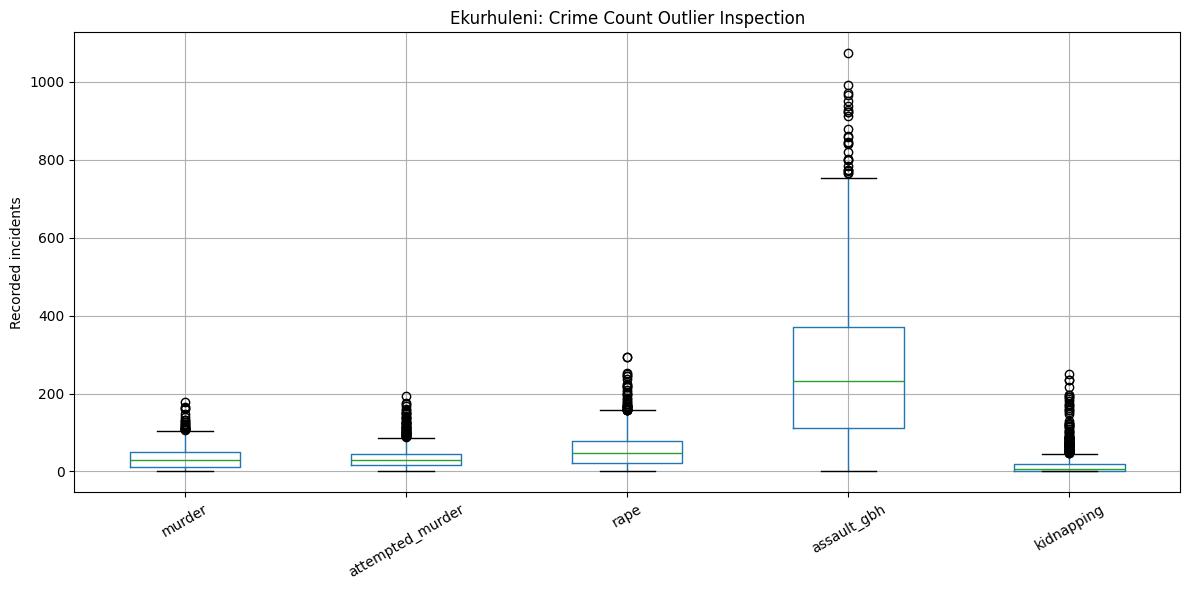

In [ ]:

import matplotlib.pyplot as plt

selected_crimes = [
    "murder",
    "attempted_murder",
    "rape",
    "assault_gbh",
    "kidnapping"
]

crime_clean[selected_crimes].boxplot(
    figsize=(12, 6)
)

plt.title("Ekurhuleni: Crime Count Outlier Inspection")
plt.ylabel("Recorded incidents")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [ ]:

outlier_summary = []

for col in selected_crimes:
    values = crime_clean[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (values < lower) |
        (values > upper)
    ).sum()

    outlier_summary.append({
        "Crime": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Potential_Outliers": outliers
    })

outlier_results = pd.DataFrame(outlier_summary)

display(outlier_results)


,Crime,Q1,Q3,IQR,Potential_Outliers
0,murder,12.0,49.0,37.0,24
1,attempted_murder,17.0,45.0,28.0,50
2,rape,23.0,77.0,54.0,39
3,assault_gbh,112.0,370.0,258.0,26
4,kidnapping,1.0,19.0,18.0,98


In [ ]:

# Keep the full cleaned dataset for reference
crime_all_years = crime_clean.copy()

# Identify years with complete selected categories
year_quality = (
    crime_clean.groupby("year")[selected_crimes]
    .apply(lambda x: x.notna().all().all())
)

print("Years with complete selected crime data:")
display(year_quality)

valid_years = year_quality[
    year_quality
].index.tolist()

crime_model_data = crime_clean[
    crime_clean["year"].isin(valid_years)
].copy()

print("\nYears retained:", len(valid_years))
print("Prepared dataset shape:", crime_model_data.shape)

print("\nRemaining missing selected crime values:")
print(crime_model_data[selected_crimes].isna().sum())


Years with complete selected crime data:


,0
year,
2005/2006,False
2006/2007,False
2007/2008,True
2008/2009,True
2009/2010,True
2010/2011,True
2011/2012,True
2012/2013,True
2013/2014,True



Years retained: 19
Prepared dataset shape: (684, 39)

Remaining missing selected crime values:
murder              0
attempted_murder    0
rape                0
assault_gbh         0
kidnapping          0
dtype: int64


In [ ]:

print("FINAL PREPARATION CHECK")

print("Shape:", crime_model_data.shape)

print("Stations:",
      crime_model_data["station"].nunique())

print("Years:",
      crime_model_data["year"].nunique())

print("Exact duplicates:",
      crime_model_data.duplicated().sum())

print("Duplicate station-year records:",
      crime_model_data.duplicated(
          ["station", "year"]
      ).sum())

print("Missing selected crime values:")
print(crime_model_data[selected_crimes].isna().sum())

print("Negative selected crime counts:")
print(
    (crime_model_data[selected_crimes] < 0)
    .sum().sum()
)

# Save prepared analytical dataset
crime_model_data.to_csv(
    "ekurhuleni_crime_prepared.csv",
    index=False
)

print("\nPrepared dataset saved successfully!")


FINAL PREPARATION CHECK
Shape: (684, 39)
Stations: 36
Years: 19
Exact duplicates: 0
Duplicate station-year records: 0
Missing selected crime values:
murder              0
attempted_murder    0
rape                0
assault_gbh         0
kidnapping          0
dtype: int64
Negative selected crime counts:
0

Prepared dataset saved successfully!



## Data Preparation Summary

The original Ekurhuleni dataset was copied
to preserve the raw observations.

Missing values were investigated by crime
category and financial year.

Years with incomplete selected violent-crime
categories were excluded from the initial
complete-year analytical dataset. No missing
crime counts were replaced with invented
values or automatically converted to zero.

Exact duplicates were checked and removed
where present.

Station and municipality labels were
standardised.

Geographic coordinates were converted
from text to numeric values.

Potential outliers were investigated using
boxplots and the Interquartile Range method.

High crime counts were not automatically
deleted because they may represent genuine
geographic concentrations.

The prepared dataset was exported to CSV
for reproducible EDA and model development.

Any remaining limitations will be documented
when interpreting the findings.


# STAGE 5: EXPLORATORY DATA ANALYSIS (EDA)

In [ ]:



# Use the dataset prepared in Stage 4
eda_df = crime_model_data.copy()

selected_crimes = [
    "murder",
    "attempted_murder",
    "rape",
    "assault_gbh",
    "kidnapping"
]

print("EDA dataset:", eda_df.shape)
print("Police stations:",
      eda_df["station"].nunique())
print("Financial years:",
      eda_df["year"].nunique())

print("\nMissing selected crime values:")
print(eda_df[selected_crimes].isna().sum())

display(eda_df.head())


EDA dataset: (684, 39)
Police stations: 36
Financial years: 19

Missing selected crime values:
murder              0
attempted_murder    0
rape                0
assault_gbh         0
kidnapping          0
dtype: int64


,year,station,loc_mn,dc_mn,longitude,latitude,dui,drug_crime,illegal_firearms,malicious_damage,...,police_detected_sexoff,contact_sexoff,sexual_offences,kidnapping,shoplifting,stock_theft,vehicle_theft,theft_from_vehicle,other_theft,year_start
72,2007/2008,actonville,ekurhuleni,ekurhuleni,28.305618,-26.219969,42,30,9,168,...,0,0.0,13,8,7,0,89,101.0,256,2007
73,2007/2008,alberton,ekurhuleni,ekurhuleni,28.139970,-26.284027,111,60,39,432,...,0,NaN,15,6,317,1,602,365.0,1289,2007
74,2007/2008,bedfordview,ekurhuleni,ekurhuleni,28.154703,-26.166956,63,20,20,194,...,0,4.0,5,8,671,0,513,181.0,1025,2007
75,2007/2008,benoni,ekurhuleni,ekurhuleni,28.334452,-26.167164,143,103,33,489,...,0,3.0,22,8,495,0,699,719.0,1637,2007
76,2007/2008,boksburg,ekurhuleni,ekurhuleni,28.259105,-26.239630,37,39,13,245,...,0,34.0,52,5,101,0,468,433.0,688,2007


In [ ]:

print("Descriptive Statistics")

display(
    eda_df[selected_crimes].describe()
)


Descriptive Statistics


,murder,attempted_murder,rape,assault_gbh,kidnapping
count,684.000000,684.000000,684.000000,684.000000,684.000000
mean,35.097953,35.590643,59.232456,266.595029,21.296784
std,29.401010,29.580408,48.721488,203.648086,37.126091
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,12.000000,17.000000,26.000000,112.000000,1.000000
50%,29.000000,28.000000,48.500000,231.000000,7.000000
75%,50.000000,45.000000,78.000000,360.000000,20.250000
max,178.000000,176.000000,294.000000,970.000000,250.000000


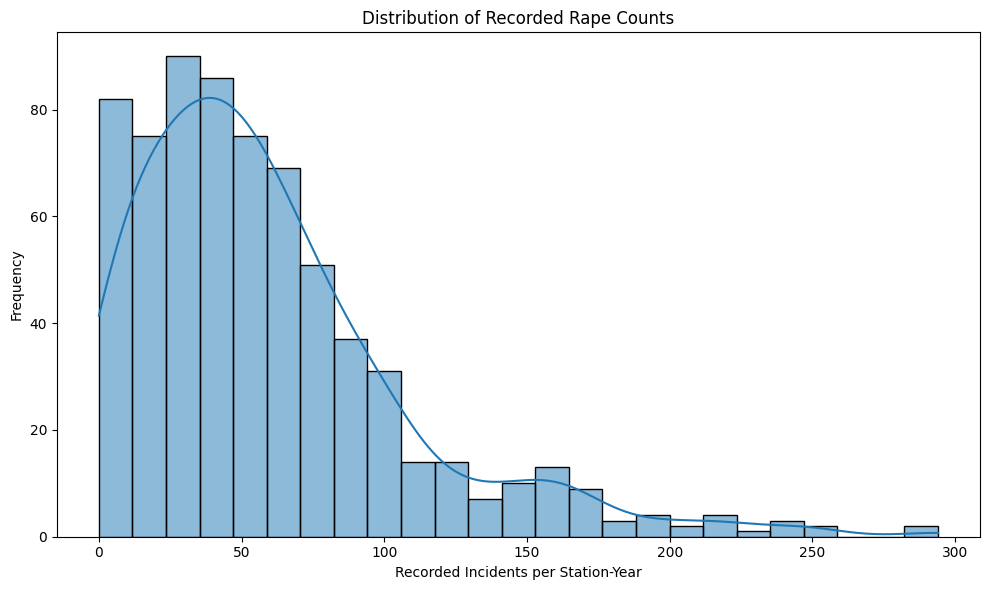

In [ ]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=eda_df,
    x="rape",
    bins=25,
    kde=True
)

plt.title("Distribution of Recorded Rape Counts")
plt.xlabel("Recorded Incidents per Station-Year")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()



### Histogram Interpretation

The histogram illustrates the distribution
of recorded rape incidents across 684
Ekurhuleni station-year observations.

The mean recorded count was approximately
59.23, while the median was 48.5.

The mean being greater than the median
indicates a positively skewed distribution.

The maximum recorded count was 294,
showing that some station-year observations
had substantially higher recorded counts
than others.

These differences may reflect variations
in population, reporting practices and
actual recorded crime patterns.

The results highlight the importance of
examining geographic concentrations rather
than relying only on the overall average.

The figures do not represent individual
victimisation probabilities.


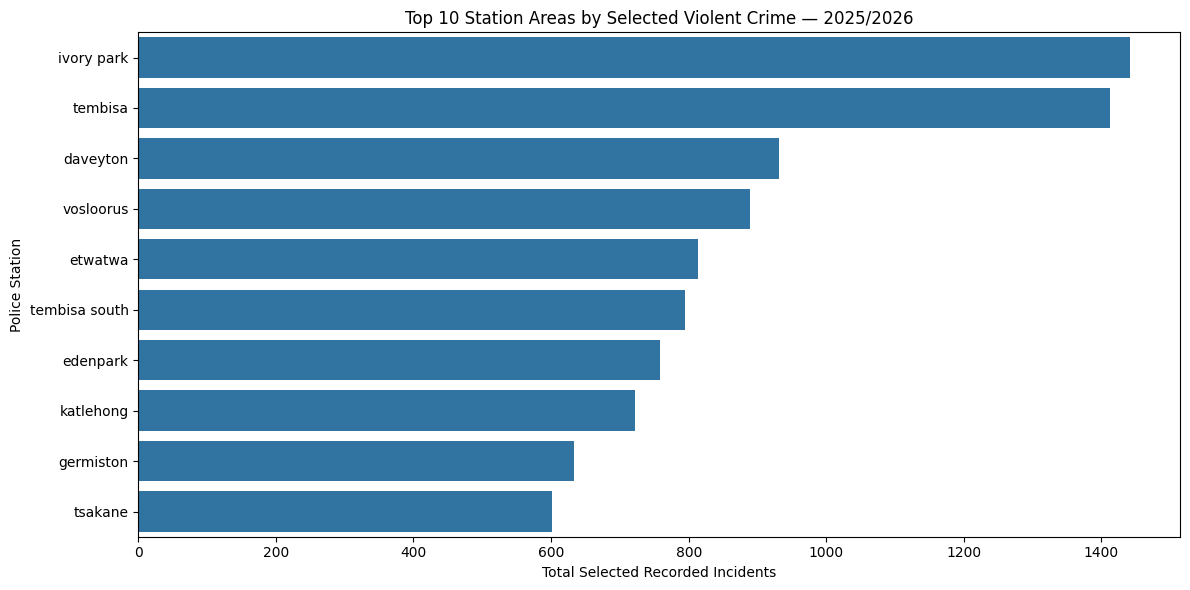

,station,selected_violent_total
738,ivory park,1442.0
750,tembisa,1413.0
729,daveyton,931.0
754,vosloorus,889.0
736,etwatwa,814.0
751,tembisa south,795.0
733,edenpark,759.0
739,katlehong,722.0
737,germiston,633.0
753,tsakane,602.0


In [ ]:

latest_year = max(eda_df["year"].unique())

latest_df = eda_df[
    eda_df["year"] == latest_year
].copy()

latest_df["selected_violent_total"] = (
    latest_df[selected_crimes].sum(axis=1)
)

top_stations = latest_df.sort_values(
    "selected_violent_total",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_stations,
    x="selected_violent_total",
    y="station"
)

plt.title(
    f"Top 10 Station Areas by Selected Violent Crime — {latest_year}"
)

plt.xlabel("Total Selected Recorded Incidents")
plt.ylabel("Police Station")

plt.tight_layout()
plt.show()

display(
    top_stations[
        ["station", "selected_violent_total"]
    ]
)



### Geographic Concentration Interpretation

The geographic analysis identified
differences in recorded violent-crime
counts between Ekurhuleni police-station
areas during the 2025/2026 financial year.

Ivory Park recorded the highest selected
violent-crime total, with 1,442 incidents.

Tembisa followed with 1,413 incidents,
while Daveyton recorded 931 incidents.

Other high-count areas included Vosloorus
with 889 and Etwatwa with 814.

These results demonstrate that selected
recorded violent-crime incidents were
not evenly distributed across stations.

The three leading areas exceeded the
project's annual hotspot threshold of
609.75 incidents.

However, higher recorded counts do not
necessarily indicate higher per-person
crime risk because police-station
populations and geographic sizes differ.


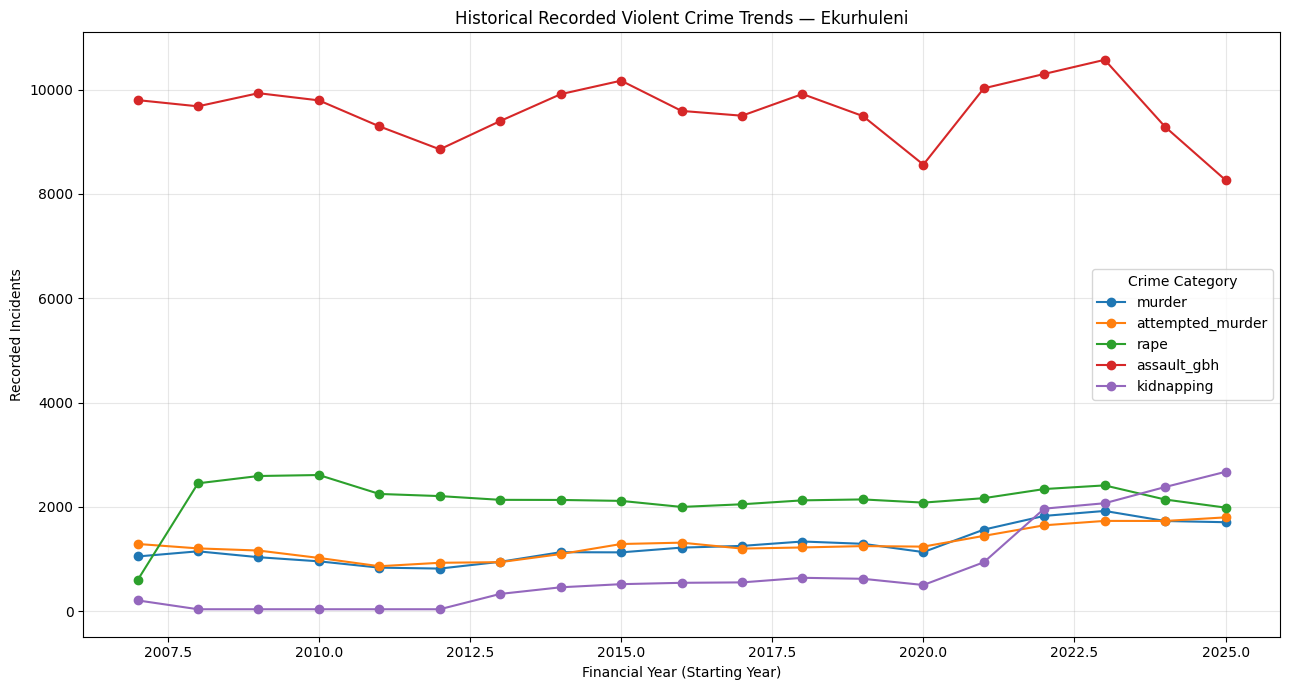

In [ ]:

annual_trends = (
    eda_df.groupby("year_start")[
        selected_crimes
    ].sum().sort_index()
)

plt.figure(figsize=(13, 7))

for crime in selected_crimes:
    plt.plot(
        annual_trends.index,
        annual_trends[crime],
        marker="o",
        label=crime
    )

plt.title(
    "Historical Recorded Violent Crime Trends — Ekurhuleni"
)

plt.xlabel("Financial Year (Starting Year)")
plt.ylabel("Recorded Incidents")

plt.legend(title="Crime Category")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Temporal Analysis Interpretation

Historical trends show that the selected
crime categories changed over time.


Recorded assault GBH incidents decreased
from 10,572 in 2023/2024 to 9,286 in
2024/2025, before declining further
to 8,265 in 2025/2026.


Recorded murder incidents decreased from
1,921 in 2023/2024 to 1,705 in 2025/2026.

In contrast, recorded kidnapping incidents
increased from 2,069 in 2023/2024 to
2,672 in 2025/2026.

These observations demonstrate that
different crime categories do not
necessarily follow the same historical
trend.

The patterns support separate monitoring
of offence categories rather than assuming
that all violent crime rises or falls
together.

These annual observations do not establish
why the changes occurred.


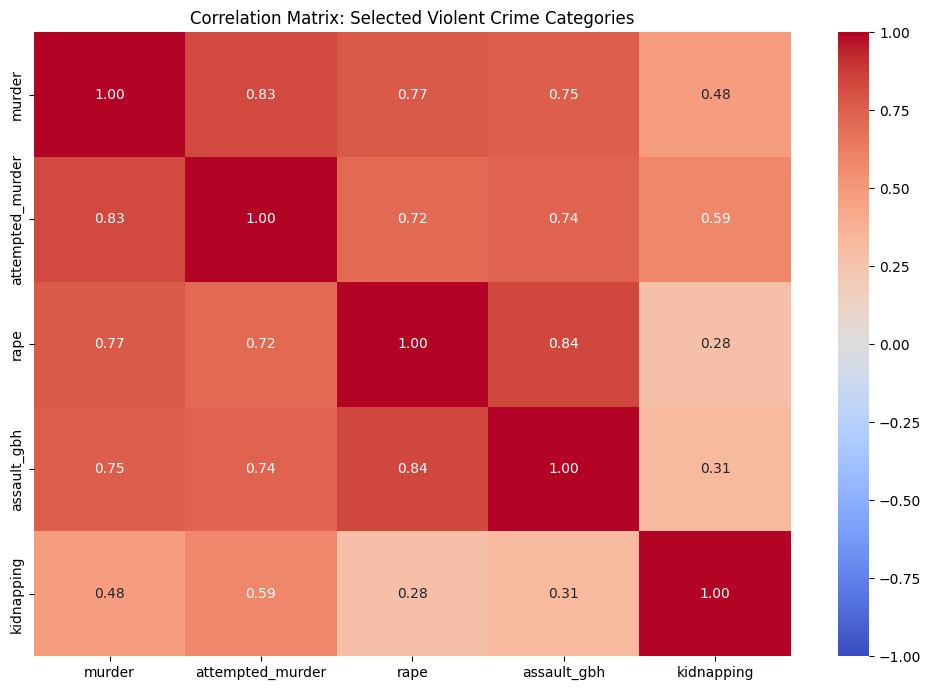

In [ ]:

correlation_matrix = (
    eda_df[selected_crimes].corr()
)
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Matrix: Selected Violent Crime Categories"
)

plt.tight_layout()
plt.show()



### Correlation Heatmap Interpretation

The correlation matrix was used to
investigate relationships between selected
violent-crime categories.

A strong positive correlation was observed
between rape and assault GBH (r = 0.84).

Murder and attempted murder also showed
a strong positive correlation (r = 0.83).

Murder and assault GBH showed a positive
correlation of approximately 0.75.

These findings indicate that station-year
observations with higher counts in one
category often also recorded higher counts
in related categories.

However, correlations do not demonstrate
that one crime category causes another.

Differences in station populations and
reporting volumes may influence these
relationships.


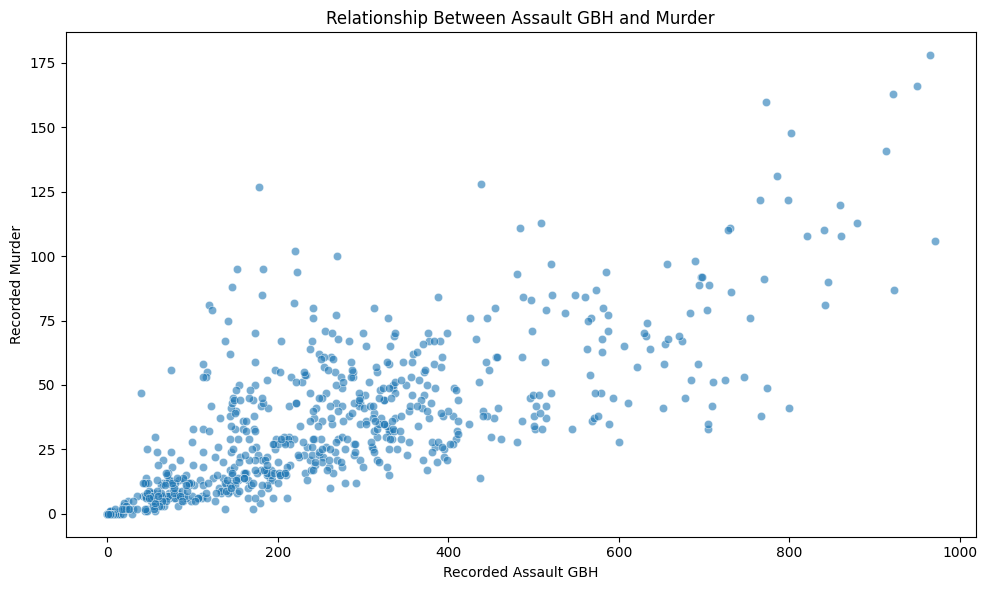

In [ ]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=eda_df,
    x="assault_gbh",
    y="murder",
    alpha=0.6
)

plt.title(
    "Relationship Between Assault GBH and Murder"
)

plt.xlabel("Recorded Assault GBH")
plt.ylabel("Recorded Murder")

plt.tight_layout()
plt.show()



### Scatter Plot Interpretation

The scatter plot examines the relationship
between recorded assault GBH and murder
counts across Ekurhuleni police-station
areas and financial years.

A positive correlation of approximately
0.75 indicates that station-year
observations with higher recorded
assault GBH counts often also have
higher murder counts.

However, the relationship is not perfect,
and correlation does not imply causation.

Differences in station population sizes,
reporting practices and other contextual
factors may influence this association.

This analysis helps identify relationships
between recorded violent-crime categories
but does not measure individual risk
to women.


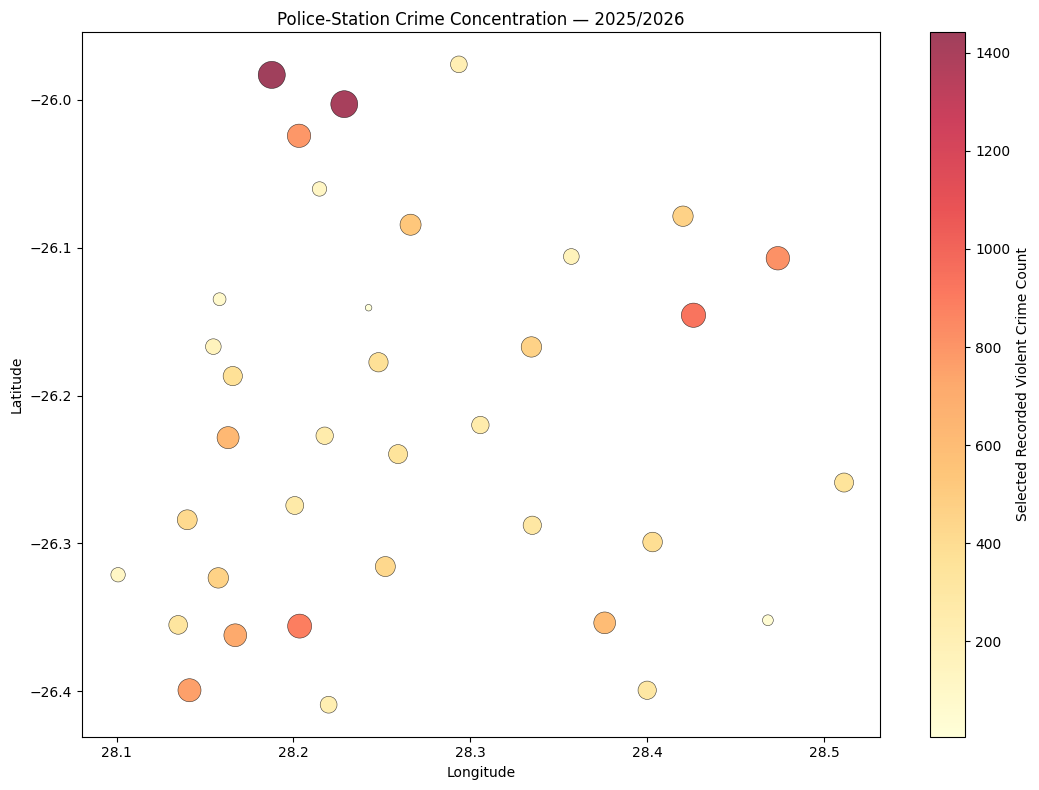

In [ ]:

map_df = latest_df.dropna(
    subset=["longitude", "latitude"]
).copy()

plt.figure(figsize=(11, 8))

scatter = plt.scatter(
    map_df["longitude"],
    map_df["latitude"],
    s=np.sqrt(
        map_df["selected_violent_total"].clip(lower=0)
    ) * 10,
    c=map_df["selected_violent_total"],
    cmap="YlOrRd",
    alpha=0.75,
    edgecolors="black",
    linewidths=0.4
)

plt.colorbar(
    scatter,
    label="Selected Recorded Violent Crime Count"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    f"Police-Station Crime Concentration — {latest_year}"
)

plt.tight_layout()
plt.show()


Three provisional comparison areas:
['ivory park', 'tembisa', 'daveyton']


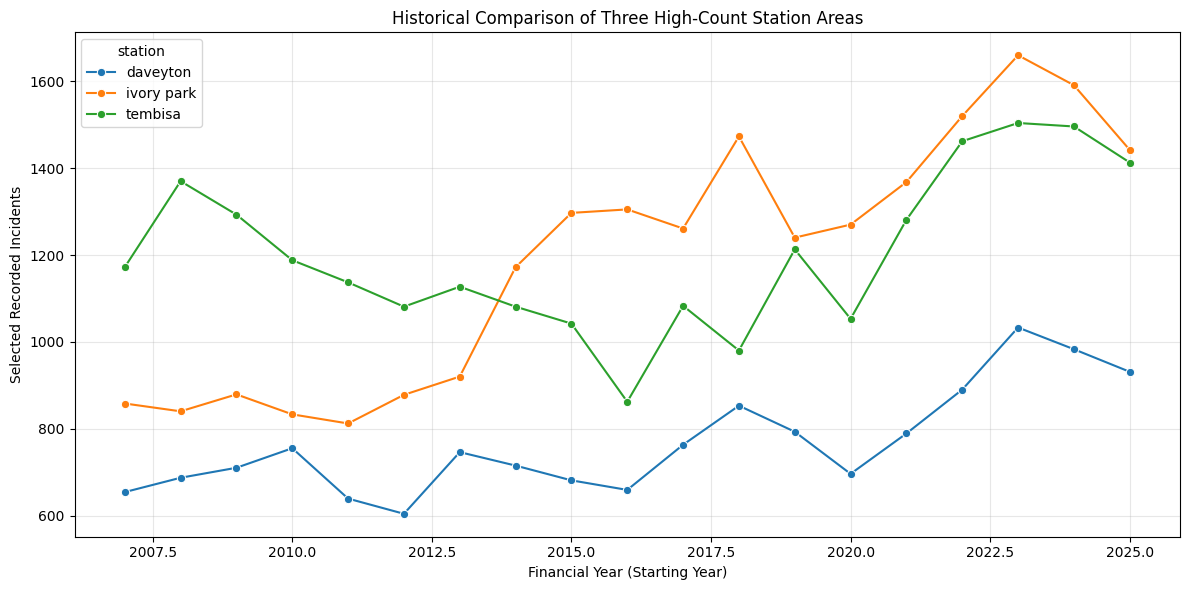

,year,station,selected_violent_total
81,2007/2008,daveyton,654.0
117,2008/2009,daveyton,687.0
153,2009/2010,daveyton,710.0
189,2010/2011,daveyton,755.0
225,2011/2012,daveyton,639.0
261,2012/2013,daveyton,604.0
297,2013/2014,daveyton,746.0
333,2014/2015,daveyton,715.0
369,2015/2016,daveyton,681.0
405,2016/2017,daveyton,659.0


In [ ]:

top_three_names = (
    top_stations["station"]
    .head(3)
    .tolist()
)

print("Three provisional comparison areas:")
print(top_three_names)

comparison_df = eda_df[
    eda_df["station"].isin(top_three_names)
].copy()

comparison_df["selected_violent_total"] = (
    comparison_df[selected_crimes].sum(axis=1)
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=comparison_df,
    x="year_start",
    y="selected_violent_total",
    hue="station",
    marker="o",
    estimator=None
)

plt.title(
    "Historical Comparison of Three High-Count Station Areas"
)

plt.xlabel("Financial Year (Starting Year)")
plt.ylabel("Selected Recorded Incidents")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(
    comparison_df[
        ["year", "station", "selected_violent_total"]
    ].sort_values(["station", "year"])
)




## Introduction

Feature Engineering is the process of
creating, transforming and selecting
variables that improve machine learning
model performance.

According to Lesson 17, the process includes:

1. Understanding data
2. Feature creation
3. Feature transformation
4. Feature encoding
5. Feature scaling
6. Feature selection

The purpose of this stage is to create
meaningful predictors for identifying
future recorded violent-crime hotspots
in Ekurhuleni.

The prediction unit is a police station
and financial year.

The target is hotspot status for the
following financial year.

Data leakage will be prevented by ensuring
the predictors contain only information
available before the target year.


In [ ]:


feature_df = crime_model_data.copy()

selected_crimes = [
    "murder",
    "attempted_murder",
    "rape",
    "assault_gbh",
    "kidnapping"
]

print("Before Feature Engineering:")
print("Shape:", feature_df.shape)

print("\nMissing selected crime values:")
print(feature_df[selected_crimes].isna().sum())

print("\nNumber of stations:")
print(feature_df["station"].nunique())

print("\nNumber of years:")
print(feature_df["year"].nunique())


Before Feature Engineering:
Shape: (684, 39)

Missing selected crime values:
murder              0
attempted_murder    0
rape                0
assault_gbh         0
kidnapping          0
dtype: int64

Number of stations:
36

Number of years:
19


# STAGE 6: FEATURE ENGINEERING

In [ ]:

# Combine five distinct selected crime categories

feature_df["violent_total"] = (
    feature_df[selected_crimes].sum(axis=1)
)

print("Total violent-crime indicator created.")

display(
    feature_df[
        ["year", "station", "violent_total"]
    ].head()
)


Total violent-crime indicator created.


,year,station,violent_total
72,2007/2008,actonville,396.0
73,2007/2008,alberton,322.0
74,2007/2008,bedfordview,120.0
75,2007/2008,benoni,444.0
76,2007/2008,boksburg,237.0


In [ ]:

feature_df["year_start"] = (
    feature_df["year"].str[:4].astype(int)
)

feature_df["year_end"] = (
    feature_df["year"].str[-4:].astype(int)
)

feature_df = feature_df.sort_values(
    ["station", "year_start"]
).reset_index(drop=True)

display(
    feature_df[
        ["station", "year", "year_start", "year_end"]
    ].head()
)


,station,year,year_start,year_end
0,actonville,2007/2008,2007,2008
1,actonville,2008/2009,2008,2009
2,actonville,2009/2010,2009,2010
3,actonville,2010/2011,2010,2011
4,actonville,2011/2012,2011,2012


In [ ]:

# Previous-year information for each station

feature_df["previous_violent_total"] = (
    feature_df.groupby("station")["violent_total"]
    .shift(1)
)

feature_df["violent_change"] = (
    feature_df["violent_total"]
    - feature_df["previous_violent_total"]
)

feature_df["previous_murder"] = (
    feature_df.groupby("station")["murder"]
    .shift(1)
)

feature_df["previous_rape"] = (
    feature_df.groupby("station")["rape"]
    .shift(1)
)

print("Historical features created.")

display(
    feature_df[
        [
            "station",
            "year",
            "violent_total",
            "previous_violent_total",
            "violent_change"
        ]
    ].head(10)
)


Historical features created.


,station,year,violent_total,previous_violent_total,violent_change
0,actonville,2007/2008,396.0,NaN,NaN
1,actonville,2008/2009,505.0,396.0,109.0
2,actonville,2009/2010,391.0,505.0,-114.0
3,actonville,2010/2011,311.0,391.0,-80.0
4,actonville,2011/2012,286.0,311.0,-25.0
5,actonville,2012/2013,240.0,286.0,-46.0
6,actonville,2013/2014,314.0,240.0,74.0
7,actonville,2014/2015,352.0,314.0,38.0
8,actonville,2015/2016,324.0,352.0,-28.0
9,actonville,2016/2017,323.0,324.0,-1.0


In [ ]:

# Determine annual 75th percentile threshold

feature_df["hotspot_threshold"] = (
    feature_df.groupby("year")["violent_total"]
    .transform(lambda x: x.quantile(0.75))
)

# Current-year hotspot classification
feature_df["Hotspot"] = (
    feature_df["violent_total"]
    >= feature_df["hotspot_threshold"]
).astype(int)

print("Current-year hotspot distribution:")
print(feature_df["Hotspot"].value_counts())

display(
    feature_df[
        [
            "year",
            "station",
            "violent_total",
            "hotspot_threshold",
            "Hotspot"
        ]
    ].head(10)
)


Current-year hotspot distribution:
Hotspot
0    513
1    171
Name: count, dtype: int64


,year,station,violent_total,hotspot_threshold,Hotspot
0,2007/2008,actonville,396.0,521.50,0
1,2008/2009,actonville,505.0,537.50,0
2,2009/2010,actonville,391.0,532.00,0
3,2010/2011,actonville,311.0,550.00,0
4,2011/2012,actonville,286.0,515.25,0
5,2012/2013,actonville,240.0,472.25,0
6,2013/2014,actonville,314.0,497.25,0
7,2014/2015,actonville,352.0,529.25,0
8,2015/2016,actonville,324.0,528.50,0
9,2016/2017,actonville,323.0,515.50,0


In [ ]:

# Shift hotspot outcome back one row
# so year t predicts the result for year t+1

feature_df["next_year_hotspot"] = (
    feature_df.groupby("station")["Hotspot"]
    .shift(-1)
)

feature_df["next_year_start"] = (
    feature_df.groupby("station")["year_start"]
    .shift(-1)
)

# Only keep genuine consecutive-year pairs
feature_df.loc[
    feature_df["next_year_start"]
    != feature_df["year_start"] + 1,
    "next_year_hotspot"
] = np.nan

print("Next-year target created.")

display(
    feature_df[
        [
            "station",
            "year",
            "Hotspot",
            "next_year_hotspot"
        ]
    ].head(10)
)


Next-year target created.


,station,year,Hotspot,next_year_hotspot
0,actonville,2007/2008,0,0.0
1,actonville,2008/2009,0,0.0
2,actonville,2009/2010,0,0.0
3,actonville,2010/2011,0,0.0
4,actonville,2011/2012,0,0.0
5,actonville,2012/2013,0,0.0
6,actonville,2013/2014,0,0.0
7,actonville,2014/2015,0,0.0
8,actonville,2015/2016,0,0.0
9,actonville,2016/2017,0,0.0


In [ ]:

feature_df["violent_total_log"] = (
    np.log1p(feature_df["violent_total"])
)

feature_df["previous_violent_log"] = (
    np.log1p(
        feature_df["previous_violent_total"]
    )
)

print("Log-transformed features created.")

display(
    feature_df[
        [
            "violent_total",
            "violent_total_log",
            "previous_violent_log"
        ]
    ].head()
)


Log-transformed features created.


,violent_total,violent_total_log,previous_violent_log
0,396.0,5.983936,NaN
1,505.0,6.226537,5.983936
2,391.0,5.971262,6.226537
3,311.0,5.743003,5.971262
4,286.0,5.659482,5.743003


In [ ]:

# Keep only records with a valid next-year target
model_df = feature_df.dropna(
    subset=[
        "next_year_hotspot",
        "previous_violent_total",
        "previous_murder",
        "previous_rape"
    ]
).copy()

model_df["next_year_hotspot"] = (
    model_df["next_year_hotspot"].astype(int)
)

# Encode station names
station_encoded = pd.get_dummies(
    model_df["station"],
    prefix="station",
    dtype=int
)

model_df = pd.concat(
    [model_df, station_encoded],
    axis=1
)

print("One-hot encoded station variables:")
print(station_encoded.shape)

print("\nModel dataset shape:")
print(model_df.shape)


One-hot encoded station variables:
(612, 36)

Model dataset shape:
(612, 87)


In [ ]:

numeric_features = [
    "violent_total",
    "previous_violent_total",
    "violent_change",
    "murder",
    "attempted_murder",
    "rape",
    "assault_gbh",
    "kidnapping",
    "year_start",
    "violent_total_log",
    "previous_violent_log"
]

station_features = station_encoded.columns.tolist()

feature_columns = (
    numeric_features + station_features
)

X = model_df[feature_columns].copy()

y = model_df["next_year_hotspot"].copy()

print("Feature matrix:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing features:")
print(X.isna().sum().sum())


Feature matrix: (612, 47)
Target shape: (612,)

Target distribution:
next_year_hotspot
0    459
1    153
Name: count, dtype: int64

Missing features:
0


In [ ]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

print("StandardScaler imported successfully.")
print("Scaling will be fitted on training data only.")


StandardScaler imported successfully.
Scaling will be fitted on training data only.


In [ ]:

print("FEATURE ENGINEERING SUMMARY")

print("\nOriginal prepared shape:")
print(crime_model_data.shape)

print("\nEngineered dataset shape:")
print(model_df.shape)

print("\nFeatures:", X.shape[1])
print("Observations:", X.shape[0])

print("\nHotspot target distribution:")
print(y.value_counts())

print("\nMissing feature values:")
print(X.isna().sum().sum())

print("\nAvailable training years:")
print(
    sorted(model_df["year_start"].unique())
)

print("\nLast target financial year:")
print(model_df["next_year_start"].max())


FEATURE ENGINEERING SUMMARY

Original prepared shape:
(684, 39)

Engineered dataset shape:
(612, 87)

Features: 47
Observations: 612

Hotspot target distribution:
next_year_hotspot
0    459
1    153
Name: count, dtype: int64

Missing feature values:
0

Available training years:
[np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

Last target financial year:
2025.0



# STAGE 7: MACHINE LEARNING MODEL BUILDING

## Introduction

Machine Learning modelling is the process
of training computer algorithms to identify
patterns in data and make predictions.

This project uses supervised binary
classification to predict whether a
police-station area will be classified
as a recorded violent-crime hotspot
in the following financial year.

The target variable is:

next_year_hotspot

1 = Hotspot
0 = Non-hotspot

Three algorithms will be trained:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

The models will be trained using historical
recorded crime features.

Data will be divided chronologically
into training, validation and testing sets.

Training data will teach the models.
Validation data will support model selection.
Testing data will provide final evaluation
on unseen later financial years.

Model performance will be assessed using
classification metrics in Stage 8.


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import numpy as np

print("Machine Learning libraries imported!")


Machine Learning libraries imported!


In [ ]:

print("Feature matrix:", X.shape)
print("Target variable:", y.shape)

print("\nHotspot distribution:")
print(y.value_counts())

print("\nMissing feature values:")
print(X.isna().sum().sum())

print("\nInfinite values:")
print(np.isinf(X.to_numpy(dtype=float)).sum())

print("\nFinancial years:")
print(sorted(model_df["year_start"].unique()))


Feature matrix: (612, 47)
Target variable: (612,)

Hotspot distribution:
next_year_hotspot
0    459
1    153
Name: count, dtype: int64

Missing feature values:
0

Infinite values:
0

Financial years:
[np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [ ]:

# Use the financial year of the outcome
data = model_df.copy().sort_values(
    ["next_year_start", "station"]
)

years = sorted(data["next_year_start"].unique())

print("Available target years:", years)

if len(years) < 6:
    raise ValueError(
        "Not enough target years for a "
        "reliable train/validation/test split."
    )

# Approximately 70% training, 15% validation,
# 15% testing, using complete financial years
n_years = len(years)

train_end = int(n_years * 0.70)
val_end = int(n_years * 0.85)

train_years = years[:train_end]
val_years = years[train_end:val_end]
test_years = years[val_end:]

train_data = data[
    data["next_year_start"].isin(train_years)
]

val_data = data[
    data["next_year_start"].isin(val_years)
]

test_data = data[
    data["next_year_start"].isin(test_years)
]

X_train = train_data[feature_columns]
y_train = train_data["next_year_hotspot"]

X_val = val_data[feature_columns]
y_val = val_data["next_year_hotspot"]

X_test = test_data[feature_columns]
y_test = test_data["next_year_hotspot"]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining target years:", train_years)
print("Validation target years:", val_years)
print("Testing target years:", test_years)

for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(name, "class distribution:",
          target.value_counts().to_dict())

    if target.nunique() < 2:
        raise ValueError(
            f"{name} contains only one class."
        )


Available target years: [np.float64(2009.0), np.float64(2010.0), np.float64(2011.0), np.float64(2012.0), np.float64(2013.0), np.float64(2014.0), np.float64(2015.0), np.float64(2016.0), np.float64(2017.0), np.float64(2018.0), np.float64(2019.0), np.float64(2020.0), np.float64(2021.0), np.float64(2022.0), np.float64(2023.0), np.float64(2024.0), np.float64(2025.0)]
Training: (396, 47)
Validation: (108, 47)
Testing: (108, 47)

Training target years: [np.float64(2009.0), np.float64(2010.0), np.float64(2011.0), np.float64(2012.0), np.float64(2013.0), np.float64(2014.0), np.float64(2015.0), np.float64(2016.0), np.float64(2017.0), np.float64(2018.0), np.float64(2019.0)]
Validation target years: [np.float64(2020.0), np.float64(2021.0), np.float64(2022.0)]
Testing target years: [np.float64(2023.0), np.float64(2024.0), np.float64(2025.0)]
Training class distribution: {0: 297, 1: 99}
Validation class distribution: {0: 81, 1: 27}
Testing class distribution: {0: 81, 1: 27}


In [ ]:

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42,
        class_weight="balanced"
    ))
])

print("Logistic Regression pipeline created.")


Logistic Regression pipeline created.


In [ ]:

# ============================================================
# STAGE 7: MACHINE LEARNING MODEL TRAINING
# Logistic Regression, Decision Tree and Random Forest
# Based on Lessons 18, 21 and 22
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# STEP 1: LOAD ENGINEERED DATA
# ------------------------------------------------------------

data = model_df.copy()

data = data.sort_values(
    ["next_year_start", "station"]
).reset_index(drop=True)

# Remove missing target or feature records
data = data.dropna(
    subset=feature_columns + ["next_year_hotspot"]
).copy()

# Verify features are numerical and finite
X_all = data[feature_columns].astype(float)

if not np.isfinite(X_all.to_numpy()).all():
    raise ValueError("Features contain infinite values.")

print("Dataset shape:", data.shape)
print("Number of features:", len(feature_columns))

# ------------------------------------------------------------
# STEP 2: CHRONOLOGICAL DATA SPLITTING
# ------------------------------------------------------------

years = sorted(data["next_year_start"].unique())

if len(years) < 6:
    raise ValueError("At least six target years are required.")

train_end = int(len(years) * 0.70)
val_end = int(len(years) * 0.85)

train_years = years[:train_end]
val_years = years[train_end:val_end]
test_years = years[val_end:]

train_df = data[
    data["next_year_start"].isin(train_years)
]

val_df = data[
    data["next_year_start"].isin(val_years)
]

test_df = data[
    data["next_year_start"].isin(test_years)
]

X_train = train_df[feature_columns].astype(float)
y_train = train_df["next_year_hotspot"].astype(int)

X_val = val_df[feature_columns].astype(float)
y_val = val_df["next_year_hotspot"].astype(int)

X_test = test_df[feature_columns].astype(float)
y_test = test_df["next_year_hotspot"].astype(int)

print("\nTRAIN / VALIDATION / TEST")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining target years:", train_years)
print("Validation target years:", val_years)
print("Testing target years:", test_years)

if y_train.nunique() < 2:
    raise ValueError("Training data requires both classes.")

# ------------------------------------------------------------
# STEP 3: CREATE THREE CLASSIFICATION MODELS
# ------------------------------------------------------------

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# ------------------------------------------------------------
# STEP 4: TRAIN AND VALIDATE ALL THREE MODELS
# ------------------------------------------------------------

results = []

os.makedirs("models", exist_ok=True)
os.makedirs("dashboard_data", exist_ok=True)

filenames = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "Random Forest": "random_forest.pkl"
}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

    joblib.dump(
        model,
        os.path.join("models", filenames[name])
    )

    print(f"{name} training completed!")

# ------------------------------------------------------------
# STEP 5: COMPARE VALIDATION RESULTS
# ------------------------------------------------------------

validation_df = pd.DataFrame(results)

validation_df = validation_df.sort_values(
    "F1", ascending=False
).reset_index(drop=True)

print("\nMODEL VALIDATION COMPARISON")
display(validation_df)

# ------------------------------------------------------------
# STEP 6: SELECT BEST VALIDATION MODEL
# ------------------------------------------------------------

best_model_name = validation_df.loc[0, "Model"]
best_model = models[best_model_name]

print("\nSelected model:", best_model_name)
print(
    "Validation F1:",
    round(validation_df.loc[0, "F1"], 4)
)

# ------------------------------------------------------------
# STEP 7: SAVE MODELS AND METADATA
# ------------------------------------------------------------

joblib.dump(best_model, "models/best_model.pkl")
joblib.dump(feature_columns, "models/feature_columns.pkl")

validation_df.to_csv(
    "dashboard_data/validation_results.csv",
    index=False
)

metadata = {
    "selected_model": best_model_name,
    "feature_columns": feature_columns,
    "train_years": [int(x) for x in train_years],
    "validation_years": [int(x) for x in val_years],
    "test_years": [int(x) for x in test_years]
}

with open("models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\nALL THREE MODELS TRAINED AND SAVED!")
print("Best model:", best_model_name)
print("Final test data reserved for Stage 8.")


Dataset shape: (612, 87)
Number of features: 47

TRAIN / VALIDATION / TEST
Training: (396, 47)
Validation: (108, 47)
Testing: (108, 47)

Training target years: [np.float64(2009.0), np.float64(2010.0), np.float64(2011.0), np.float64(2012.0), np.float64(2013.0), np.float64(2014.0), np.float64(2015.0), np.float64(2016.0), np.float64(2017.0), np.float64(2018.0), np.float64(2019.0)]
Validation target years: [np.float64(2020.0), np.float64(2021.0), np.float64(2022.0)]
Testing target years: [np.float64(2023.0), np.float64(2024.0), np.float64(2025.0)]

Training Logistic Regression...
Logistic Regression training completed!

Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!

MODEL VALIDATION COMPARISON


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.944444,0.818182,1.000000,0.900000
1,Random Forest,0.935185,0.833333,0.925926,0.877193
2,Decision Tree,0.907407,0.793103,0.851852,0.821429



Selected model: Logistic Regression
Validation F1: 0.9

ALL THREE MODELS TRAINED AND SAVED!
Best model: Logistic Regression
Final test data reserved for Stage 8.



# STAGE 8: MODEL VALIDATION AND EVALUATION

## Introduction

Model evaluation measures how well a
trained Machine Learning model performs
on previously unseen observations.

Three classification models were trained:
Logistic Regression, Decision Tree and
Random Forest.

Logistic Regression achieved the highest
validation F1-score of 0.9000 and was
selected for final testing.

The final evaluation uses later financial
years that were not used for training
or model selection.

Metrics include:
- Confusion Matrix
- Accuracy
- Precision
- Recall
- F1-score

The objective is to assess how reliably
the model identifies recorded violent-crime
hotspots in Ekurhuleni.


Selected model: Logistic Regression

FINAL TEST RESULTS
Accuracy: 0.9444
Precision: 0.8387
Recall: 0.963
F1-score: 0.8966

Confusion Matrix:
[[76  5]
 [ 1 26]]


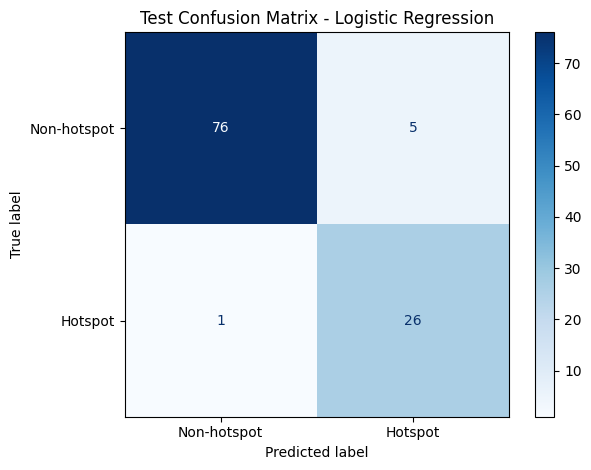


CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Non-hotspot       0.99      0.94      0.96        81
     Hotspot       0.84      0.96      0.90        27

    accuracy                           0.94       108
   macro avg       0.91      0.95      0.93       108
weighted avg       0.95      0.94      0.95       108


Files exported successfully!
Model evaluation completed.


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.944444,0.83871,0.962963,0.896552


,station,year,year_start,next_year_start,violent_total,Actual_Hotspot,Predicted_Hotspot,Hotspot_Probability
504,actonville,2022/2023,2022,2023.0,306.0,0,0,0.002224
505,alberton,2022/2023,2022,2023.0,421.0,0,0,0.006636
506,bedfordview,2022/2023,2022,2023.0,122.0,0,0,0.001245
507,benoni,2022/2023,2022,2023.0,504.0,0,0,0.167654
508,boksburg,2022/2023,2022,2023.0,312.0,0,0,0.002727


In [ ]:

# =====================================================
# STAGE 8: MACHINE LEARNING MODEL EVALUATION
# Based on Lessons 19, 20 and 21
# =====================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

os.makedirs("dashboard_data", exist_ok=True)

# -----------------------------------------------------
# 1. LOAD SELECTED MODEL
# -----------------------------------------------------

best_model = joblib.load("models/best_model.pkl")
feature_columns = joblib.load(
    "models/feature_columns.pkl"
)

print("Selected model:", best_model_name)

# -----------------------------------------------------
# 2. PREDICT ON UNSEEN TEST DATA
# -----------------------------------------------------

test_predictions = best_model.predict(X_test)

test_probabilities = best_model.predict_proba(
    X_test
)[:, 1]

# -----------------------------------------------------
# 3. CLASSIFICATION METRICS
# -----------------------------------------------------

test_accuracy = accuracy_score(
    y_test, test_predictions
)

test_precision = precision_score(
    y_test, test_predictions,
    zero_division=0
)

test_recall = recall_score(
    y_test, test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    y_test, test_predictions,
    zero_division=0
)

print("\nFINAL TEST RESULTS")
print("Accuracy:", round(test_accuracy, 4))
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))
print("F1-score:", round(test_f1, 4))

# -----------------------------------------------------
# 4. CONFUSION MATRIX
# -----------------------------------------------------

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-hotspot", "Hotspot"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    f"Test Confusion Matrix - {best_model_name}"
)
plt.tight_layout()
plt.show()

# -----------------------------------------------------
# 5. CLASSIFICATION REPORT
# -----------------------------------------------------

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["Non-hotspot", "Hotspot"],
        zero_division=0
    )
)

# -----------------------------------------------------
# 6. EXPORT FINAL METRICS
# -----------------------------------------------------

evaluation_results = pd.DataFrame([{
    "Model": best_model_name,
    "Accuracy": test_accuracy,
    "Precision": test_precision,
    "Recall": test_recall,
    "F1": test_f1
}])

evaluation_results.to_csv(
    "dashboard_data/model_evaluation.csv",
    index=False
)

# -----------------------------------------------------
# 7. EXPORT TEST PREDICTIONS
# -----------------------------------------------------

test_results = test_df[
    ["station", "year", "year_start",
     "next_year_start", "violent_total"]
].copy()

test_results["Actual_Hotspot"] = (
    y_test.to_numpy()
)

test_results["Predicted_Hotspot"] = (
    test_predictions
)

test_results["Hotspot_Probability"] = (
    test_probabilities
)

test_results.to_csv(
    "dashboard_data/test_predictions.csv",
    index=False
)

# -----------------------------------------------------
# 8. SAVE CONFUSION MATRIX VALUES
# -----------------------------------------------------

confusion_df = pd.DataFrame(
    cm,
    index=["Actual Non-hotspot", "Actual Hotspot"],
    columns=["Predicted Non-hotspot",
             "Predicted Hotspot"]
)

confusion_df.to_csv(
    "dashboard_data/confusion_matrix.csv"
)

print("\nFiles exported successfully!")
print("Model evaluation completed.")

display(evaluation_results)
display(test_results.head())



## Model Evaluation Interpretation

### Final Test Results

The selected Logistic Regression model was
evaluated using held-out observations from
later financial years.

The model achieved:

- Accuracy: 94.44%
- Precision: 83.87%
- Recall: 96.30%
- F1-score: 89.66%

### Confusion Matrix Interpretation

The model was evaluated on 108 observations.

The confusion matrix showed:

- True Negatives: 76
- False Positives: 5
- False Negatives: 1
- True Positives: 26

The model correctly classified 102 out of
108 observations.

It successfully identified 26 of the 27
actual hotspot observations, resulting
in recall of 96.30%.

The five false positives indicate that
some areas were predicted as hotspots
even though their observed labels were
non-hotspots.

### Model Performance

The high F1-score indicates a strong
balance between precision and recall
for the evaluated data.

Logistic Regression was selected based
on its validation performance rather
than its final test results.

### Limitations

The model predicts relative next-year
recorded violent-crime hotspot status.

It does not predict exact future crime
counts or individual women's safety.

Hotspot labels are defined using the
observed annual distribution of
recorded incidents.

Therefore, the final evaluation should
be interpreted as a historical backtest
rather than a guarantee of performance
in future years.



## Predictive Modelling and Forecasting Scope

### Prediction Objective

This project uses supervised Machine
Learning to predict whether an Ekurhuleni
police-station area will belong to the
highest 25% of selected recorded
violent-crime totals in the following
financial year.

The models use historical station-level
crime information to predict the next-
year hotspot classification.

### Forecasting Approach

The project implements temporal hotspot
classification using historical features
and next-year target labels.

A chronological training and testing
approach was used to evaluate performance
on later observations.

This is different from traditional
time-series forecasting, which estimates
future numerical crime counts.

### Forecasting Limitations

The model does not produce a numerical
forecast of future crime incidents.

The observed annual 75th-percentile
threshold is used to define historical
hotspot labels.

The future year's actual threshold is
unknown before that year's crime data
are collected.

The final test results therefore measure
historical predictive classification
performance, not the accuracy of a new
operational future-year forecast.

### Future Development

Future work could include:

- SARIMA or other time-series methods to
  forecast future recorded-crime totals.
- Prediction intervals to communicate
  uncertainty in numerical forecasts.
- Prospective hotspot predictions using
  decision thresholds fixed before the
  forecast year.
- Population-adjusted analysis where
  appropriate station-level denominators
  become available.

The current classification results remain
valid for the stated historical evaluation
task and are not presented as numerical
future-crime forecasts.



# STAGE 9: PATTERN DISCOVERY AND TEMPORAL ANALYSIS

## Introduction

Pattern discovery investigates meaningful
relationships, similarities and changes
within historical data.

This project investigates recorded violent-
crime patterns across Ekurhuleni police-
station areas.

The analysis includes:

1. Unsupervised clustering
2. Historical temporal trends
3. Geographic comparison
4. Comparison of three hotspot areas

K-Means clustering will group police
stations according to similarities in
their recorded violent-crime profiles.

Clustering does not use hotspot labels
to learn the groups.

The analysis will distinguish association
from causation and will not interpret
clusters as proof that communities are
inherently dangerous.


In [ ]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

pattern_df = crime_model_data.copy()

crime_categories = [
    "murder",
    "attempted_murder",
    "rape",
    "assault_gbh",
    "kidnapping"
]

pattern_df["violent_total"] = (
    pattern_df[crime_categories].sum(axis=1)
)

print("Pattern analysis dataset:", pattern_df.shape)
print("Police stations:",
      pattern_df["station"].nunique())

print("Financial years:",
      pattern_df["year"].nunique())


Pattern analysis dataset: (684, 40)
Police stations: 36
Financial years: 19


In [ ]:

station_profiles = (
    pattern_df.groupby("station")[crime_categories]
    .mean()
    .reset_index()
)

station_profiles["mean_violent_total"] = (
    station_profiles[crime_categories].sum(axis=1)
)

print("Station profiles:", station_profiles.shape)

display(station_profiles.head())


Station profiles: (36, 7)


,station,murder,attempted_murder,rape,assault_gbh,kidnapping,mean_violent_total
0,actonville,26.421053,20.263158,33.315789,221.315789,7.526316,308.842105
1,alberton,28.736842,35.947368,43.210526,196.368421,26.052632,330.315789
2,bedfordview,6.157895,16.526316,10.631579,56.947368,15.842105,106.105263
3,benoni,45.947368,45.210526,65.000000,292.631579,22.789474,471.578947
4,boksburg,30.315789,24.789474,36.105263,154.000000,17.578947,262.789474


In [ ]:

scaler_cluster = StandardScaler()

X_cluster = scaler_cluster.fit_transform(
    station_profiles[crime_categories]
)

print("Scaled clustering dataset:")
print(X_cluster.shape)


Scaled clustering dataset:
(36, 5)


,Clusters,Silhouette
0,2,0.557310
1,3,0.440897
2,4,0.358223
3,5,0.353837
4,6,0.349707


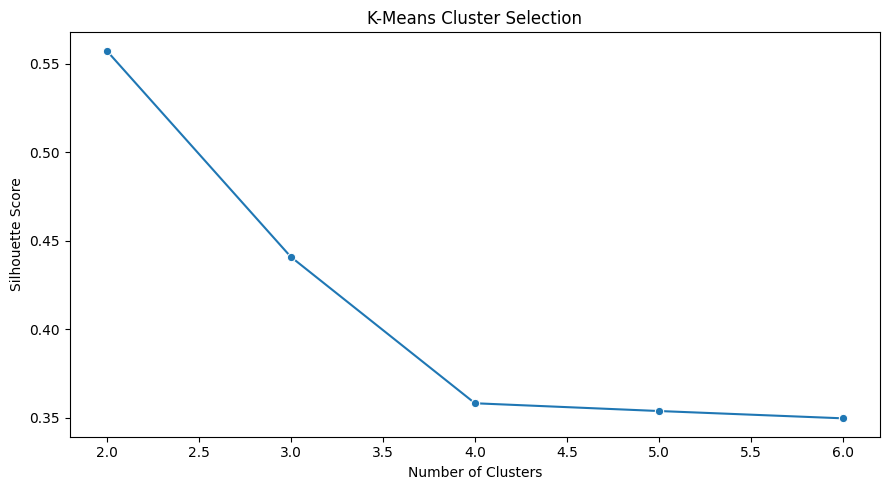

In [ ]:

silhouette_results = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    score = silhouette_score(
        X_cluster, labels
    )

    silhouette_results.append({
        "Clusters": k,
        "Silhouette": score
    })

silhouette_df = pd.DataFrame(
    silhouette_results
)

display(silhouette_df)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=silhouette_df,
    x="Clusters",
    y="Silhouette",
    marker="o"
)

plt.title("K-Means Cluster Selection")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()


In [ ]:

best_k = int(
    silhouette_df.sort_values(
        "Silhouette", ascending=False
    ).iloc[0]["Clusters"]
)

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

station_profiles["Cluster"] = (
    kmeans_model.fit_predict(X_cluster)
)

print("Selected number of clusters:", best_k)

print("\nStations per cluster:")
print(station_profiles["Cluster"].value_counts())

display(
    station_profiles[
        ["station", "Cluster", "mean_violent_total"]
    ].sort_values(
        ["Cluster", "mean_violent_total"],
        ascending=[True, False]
    )
)


Selected number of clusters: 2

Stations per cluster:
Cluster
1    31
0     5
Name: count, dtype: int64


,station,Cluster,mean_violent_total
30,tembisa,0,1202.000000
18,ivory park,0,1190.473684
33,tsakane,0,948.315789
34,vosloorus,0,689.157895
19,katlehong,0,674.421053
16,etwatwa,1,798.526316
9,daveyton,1,767.421053
13,edenpark,1,585.736842
29,springs,1,492.789474
17,germiston,1,484.842105


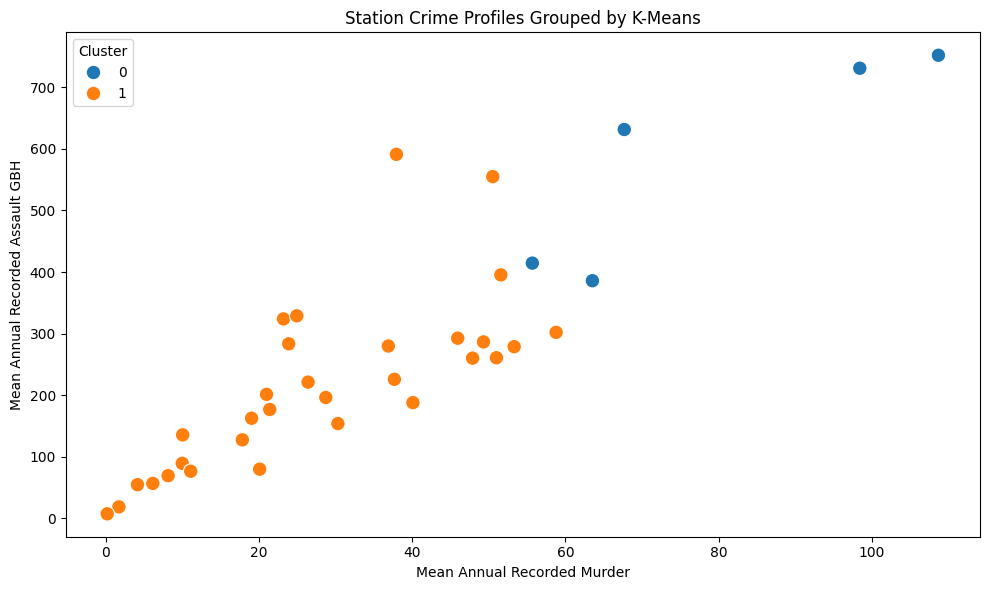

In [ ]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=station_profiles,
    x="murder",
    y="assault_gbh",
    hue="Cluster",
    palette="tab10",
    s=110
)

plt.title(
    "Station Crime Profiles Grouped by K-Means"
)

plt.xlabel("Mean Annual Recorded Murder")
plt.ylabel("Mean Annual Recorded Assault GBH")

plt.tight_layout()
plt.show()


In [ ]:

cluster_summary = (
    station_profiles.groupby("Cluster")[
        crime_categories + ["mean_violent_total"]
    ].mean().round(2)
)

print("Cluster crime profiles:")
display(cluster_summary)


Cluster crime profiles:


,murder,attempted_murder,rape,assault_gbh,kidnapping,mean_violent_total
Cluster,,,,,,
0,78.80,86.80,143.13,582.91,49.24,940.87
1,28.05,27.33,45.70,215.58,16.79,333.45



## Clustering Interpretation

K-Means clustering was used to group
Ekurhuleni police-station areas according
to similarities in their historical
recorded violent-crime profiles.

Five numerical crime categories were
standardised prior to clustering.

The number of clusters was selected
using silhouette-score comparison.

Cluster membership reflects similarities
in recorded counts, not proven causes
of violence or individual safety risk.

Differences in station population,
reporting practices and geographic size
may affect the observed patterns.


In [ ]:

latest_year = sorted(pattern_df["year"].unique())[-1]

latest_stations = pattern_df[
    pattern_df["year"] == latest_year
].copy()

threshold = (
    latest_stations["violent_total"].quantile(0.75)
)

latest_stations["Hotspot"] = (
    latest_stations["violent_total"] >= threshold
).astype(int)

top_three = (
    latest_stations[
        latest_stations["Hotspot"] == 1
    ]
    .sort_values("violent_total", ascending=False)
    .head(3)
)

top_three_names = top_three["station"].tolist()

print("Financial year:", latest_year)
print("Hotspot threshold:", threshold)
print("Three selected hotspot areas:")

display(
    top_three[
        ["station", "violent_total", "Hotspot"]
    ]
)


Financial year: 2025/2026
Hotspot threshold: 609.75
Three selected hotspot areas:


,station,violent_total,Hotspot
738,ivory park,1442.0,1
750,tembisa,1413.0,1
729,daveyton,931.0,1


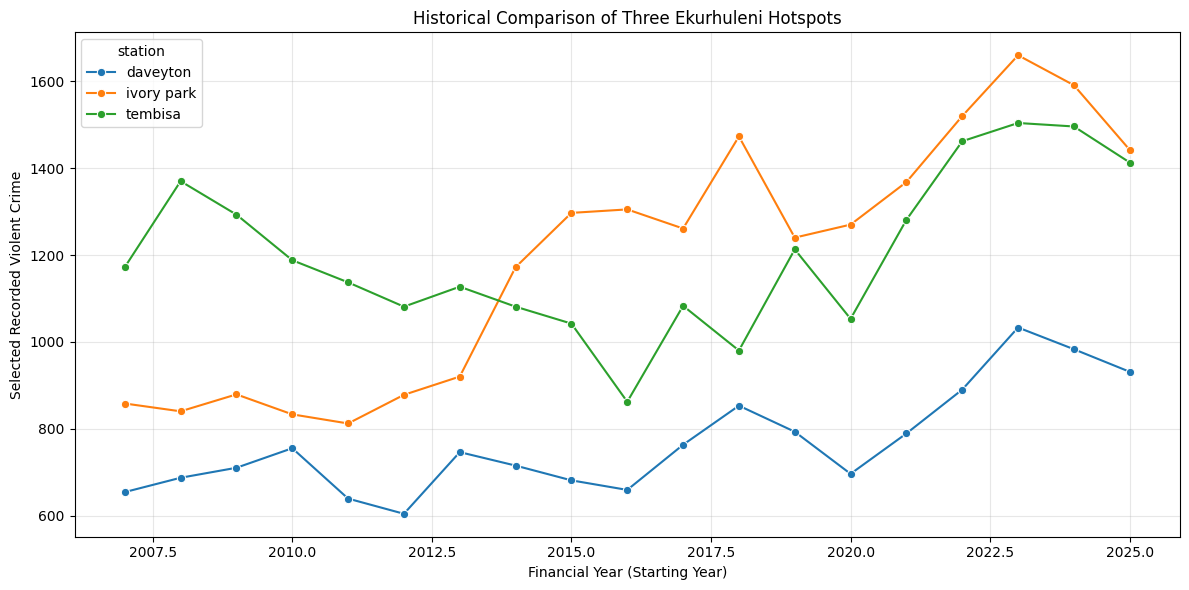

In [ ]:

three_hotspots = pattern_df[
    pattern_df["station"].isin(top_three_names)
].copy()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=three_hotspots,
    x="year_start",
    y="violent_total",
    hue="station",
    marker="o",
    estimator=None
)

plt.title(
    "Historical Comparison of Three Ekurhuleni Hotspots"
)

plt.xlabel("Financial Year (Starting Year)")
plt.ylabel("Selected Recorded Violent Crime")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,murder,attempted_murder,rape,assault_gbh,kidnapping
station,,,,,
daveyton,57,55,99.0,621,99
ivory park,160,149,189.0,773,171
tembisa,90,143,139.0,845,196


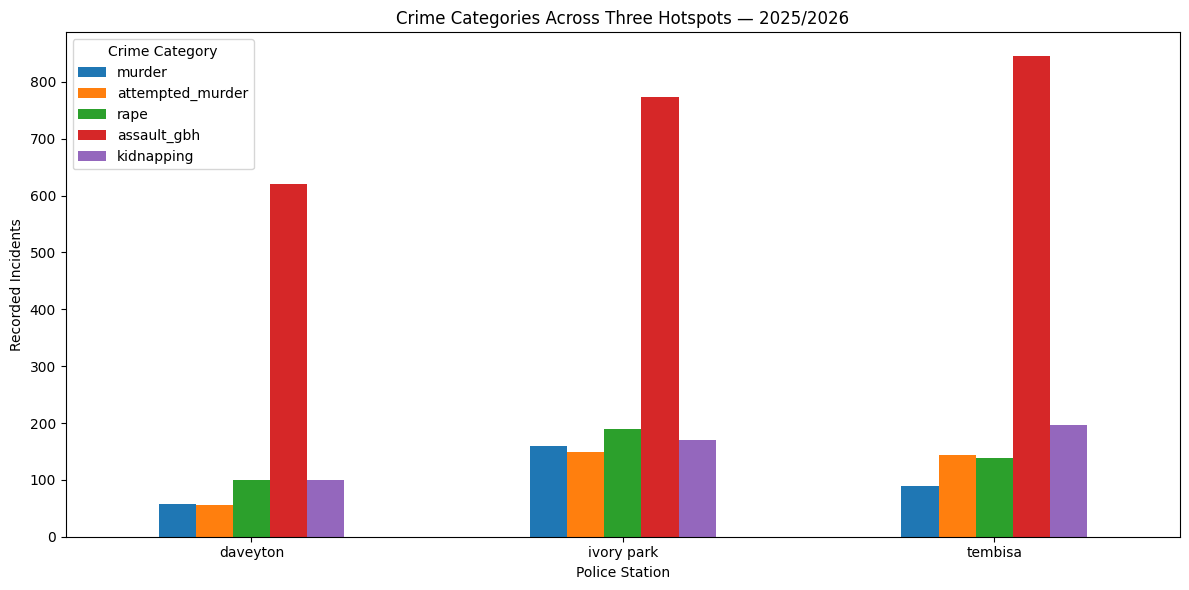

In [ ]:

three_category_comparison = (
    latest_stations[
        latest_stations["station"].isin(top_three_names)
    ]
    .set_index("station")[crime_categories]
)

display(three_category_comparison)

three_category_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    f"Crime Categories Across Three Hotspots — {latest_year}"
)

plt.xlabel("Police Station")
plt.ylabel("Recorded Incidents")
plt.xticks(rotation=0)
plt.legend(title="Crime Category")
plt.tight_layout()
plt.show()



## Interpretation of Three Selected Hotspots

### Geographic Comparison

Three police-station areas were selected
based on the highest recorded totals for
the selected violent-crime categories
during 2025/2026.

The results were:

- Ivory Park: 1,442 incidents
- Tembisa: 1,413 incidents
- Daveyton: 931 incidents

All three exceeded the annual 75th-
percentile hotspot threshold of 609.75.

### Crime Category Comparison

Assault GBH contributed the highest
individual category count in all three
selected station areas.

- Tembisa: 845 assault GBH incidents
- Ivory Park: 773 assault GBH incidents
- Daveyton: 621 assault GBH incidents

Ivory Park recorded 189 rape incidents
and 160 murders.

Tembisa recorded 139 rape incidents
and 90 murders.

This demonstrates that station areas
with high combined violent-crime totals
may have different crime-category profiles.

### Interpretation

The findings show that recorded violent
crime is not distributed equally across
Ekurhuleni police-station areas.

Comparing crime categories and historical
trends can help identify areas for
further safety investigation and
resource planning.

However, recorded counts are not adjusted
for local population size.

The results cannot establish the causes
of violence or directly measure
women-specific victimisation.


In [ ]:

three_hotspots = three_hotspots.sort_values(
    ["station", "year_start"]
)

three_hotspots["annual_change"] = (
    three_hotspots.groupby("station")[
        "violent_total"
    ].diff()
)

print("Annual changes in recorded incidents:")

display(
    three_hotspots[
        ["station", "year", "violent_total",
         "annual_change"]
    ].tail(15)
)


Annual changes in recorded incidents:


,station,year,violent_total,annual_change
246,tembisa,2011/2012,1137.0,-51.0
282,tembisa,2012/2013,1081.0,-56.0
318,tembisa,2013/2014,1127.0,46.0
354,tembisa,2014/2015,1081.0,-46.0
390,tembisa,2015/2016,1042.0,-39.0
426,tembisa,2016/2017,862.0,-180.0
462,tembisa,2017/2018,1083.0,221.0
498,tembisa,2018/2019,980.0,-103.0
534,tembisa,2019/2020,1213.0,233.0
570,tembisa,2020/2021,1053.0,-160.0


In [ ]:

import os
import joblib

os.makedirs("dashboard_data", exist_ok=True)
os.makedirs("models", exist_ok=True)

station_profiles.to_csv(
    "dashboard_data/station_clusters.csv",
    index=False
)

cluster_summary.to_csv(
    "dashboard_data/cluster_summary.csv"
)

three_hotspots.to_csv(
    "dashboard_data/three_hotspots.csv",
    index=False
)

three_category_comparison.to_csv(
    "dashboard_data/three_hotspot_categories.csv"
)

latest_stations.to_csv(
    "dashboard_data/hotspot_areas.csv",
    index=False
)

joblib.dump(
    kmeans_model,
    "models/kmeans_model.pkl"
)

joblib.dump(
    scaler_cluster,
    "models/cluster_scaler.pkl"
)

print("Pattern analysis successfully exported!")


Pattern analysis successfully exported!



## Pattern Discovery Conclusion

### 1. Observed Crime Hotspots

The observed hotspot analysis used actual
recorded SAPS crime statistics for the
2025/2026 financial year.

Hotspots were identified using the annual
75th-percentile threshold of 609.75
recorded incidents.

The three highest-count station areas were:

- Ivory Park: 1,442 incidents
- Tembisa: 1,413 incidents
- Daveyton: 931 incidents

These are observed historical crime totals,
not predictions generated by the Machine
Learning classifier.

### 2. Machine Learning Hotspot Prediction

A separate supervised Machine Learning
analysis was conducted using Logistic
Regression, Decision Tree and Random Forest.

The objective was to predict whether a
station area would belong to the highest
25% of recorded violent-crime totals
in the following financial year.

Logistic Regression was selected based
on validation performance.

Its final historical test results were:

- Accuracy: 94.44%
- Precision: 83.87%
- Recall: 96.30%
- F1-score: 89.66%

These results describe classification
performance on held-out historical
observations, rather than predictions
for an entirely new future year.

### 3. Pattern Discovery

K-Means clustering analysed similarities
between the historical recorded-crime
profiles of 36 station areas.

Two clusters were selected, containing
5 and 31 station areas respectively.

The clustering analysis identified
groups with similar crime profiles.

Cluster membership does not directly
measure individual danger or women's
personal safety.

### 4. Overall Interpretation

The observed hotspot analysis, predictive
classification and K-Means clustering
provide complementary findings.

Observed hotspots identify areas with
high recorded incident totals.

Predictive classification evaluates whether
historical features can identify
next-year hotspot status.

Clustering groups station areas based on
similarities in recorded-crime profiles.

Together, these analyses support further
investigation of geographic and historical
crime patterns in Ekurhuleni.

The results cannot establish the causes
of violence or directly measure women's
individual victimisation risk.


In [ ]:

import os

os.makedirs("dashboard_data", exist_ok=True)

# Cleaned historical observations
eda_df.to_csv(
    "dashboard_data/cleaned_crime.csv",
    index=False
)

# Annual crime trends
annual_trends.to_csv(
    "dashboard_data/annual_trends.csv"
)

# Latest-year station observations
latest_df.to_csv(
    "dashboard_data/latest_year_stations.csv",
    index=False
)

# Validation results
validation_df.to_csv(
    "dashboard_data/validation_results.csv",
    index=False
)

print("Dashboard data exports completed.")
print("\nAvailable files:")

for filename in sorted(os.listdir("dashboard_data")):
    print(filename)


Dashboard data exports completed.

Available files:
annual_trends.csv
cleaned_crime.csv
cluster_summary.csv
confusion_matrix.csv
engineered_data.csv
hotspot_areas.csv
latest_year_stations.csv
model_evaluation.csv
station_clusters.csv
test_predictions.csv
three_area_comparison.csv
three_hotspot_categories.csv
three_hotspots.csv
validation_results.csv


In [ ]:

# ===================================================
# STAGE 10: EXPORT ALL STREAMLIT DASHBOARD DATA
# ===================================================

import os
import pandas as pd

os.makedirs("dashboard_data", exist_ok=True)

exports = {
    "cleaned_crime.csv": eda_df,
    "annual_trends.csv": annual_trends,
    "latest_year_stations.csv": latest_df,
    "validation_results.csv": validation_df,
    "model_evaluation.csv": evaluation_results,
    "test_predictions.csv": test_results,
    "confusion_matrix.csv": confusion_df,
    "station_clusters.csv": station_profiles,
    "cluster_summary.csv": cluster_summary,
    "three_hotspots.csv": three_hotspots,
    "hotspot_areas.csv": latest_stations,
    "three_hotspot_categories.csv": three_category_comparison
}

for filename, dataframe in exports.items():
    path = os.path.join("dashboard_data", filename)
    dataframe.to_csv(path, index=(filename in [
        "confusion_matrix.csv",
        "cluster_summary.csv",
        "three_hotspot_categories.csv"
    ]))
    print("Saved:", path)

print("\nALL DASHBOARD FILES EXPORTED!")

print("\nFiles in dashboard_data:")
for filename in sorted(os.listdir("dashboard_data")):
    print("-", filename)


Saved: dashboard_data/cleaned_crime.csv
Saved: dashboard_data/annual_trends.csv
Saved: dashboard_data/latest_year_stations.csv
Saved: dashboard_data/validation_results.csv
Saved: dashboard_data/model_evaluation.csv
Saved: dashboard_data/test_predictions.csv
Saved: dashboard_data/confusion_matrix.csv
Saved: dashboard_data/station_clusters.csv
Saved: dashboard_data/cluster_summary.csv
Saved: dashboard_data/three_hotspots.csv
Saved: dashboard_data/hotspot_areas.csv
Saved: dashboard_data/three_hotspot_categories.csv

ALL DASHBOARD FILES EXPORTED!

Files in dashboard_data:
- annual_trends.csv
- cleaned_crime.csv
- cluster_summary.csv
- confusion_matrix.csv
- engineered_data.csv
- hotspot_areas.csv
- latest_year_stations.csv
- model_evaluation.csv
- station_clusters.csv
- test_predictions.csv
- three_area_comparison.csv
- three_hotspot_categories.csv
- three_hotspots.csv
- validation_results.csv


In [ ]:

import shutil
from google.colab import files

# Package both folders for your Streamlit project
shutil.make_archive(
    "Ekurhuleni_Dashboard_Results",
    "zip",
    root_dir=".",
    base_dir="dashboard_data"
)

shutil.make_archive(
    "Ekurhuleni_Trained_Models",
    "zip",
    root_dir=".",
    base_dir="models"
)

files.download("Ekurhuleni_Dashboard_Results.zip")
files.download("Ekurhuleni_Trained_Models.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os

print("DASHBOARD DATA FILES")
print("=" * 35)

folder = "/content/dashboard_data"

if os.path.exists(folder):
    for filename in sorted(os.listdir(folder)):
        print("✅", filename)
else:
    print("Dashboard data folder not found.")


DASHBOARD DATA FILES
✅ annual_trends.csv
✅ cleaned_crime.csv
✅ cluster_summary.csv
✅ confusion_matrix.csv
✅ engineered_data.csv
✅ hotspot_areas.csv
✅ latest_year_stations.csv
✅ model_evaluation.csv
✅ station_clusters.csv
✅ test_predictions.csv
✅ three_area_comparison.csv
✅ three_hotspot_categories.csv
✅ three_hotspots.csv
✅ validation_results.csv



# STAGE 11: SECOND DATASET INTEGRATION

## Dataset 2: Statistics South Africa Census 2022

The second dataset is the Statistics South
Africa Census 2022 Municipal Fact Sheet,
Report 03-01-82.

The dataset contains demographic and
household information for South African
municipalities.

For this project, Ekurhuleni statistics
from the 2011 and 2022 censuses were
selected for analysis.

The objective is to provide demographic
context for interpreting the SAPS crime
statistics.

Unlike the police-station crime dataset,
the Census figures describe the entire
Ekurhuleni municipality.

Therefore, the data will be integrated
at the interpretation and dashboard
level rather than being incorrectly
joined to individual police stations.


In [ ]:

# ==============================================
# DATASET 2: STATS SA CENSUS INTEGRATION
# ==============================================

import pandas as pd
import os

census_df = pd.DataFrame({
    "Year": [2011, 2022],
    "Municipality": ["Ekurhuleni", "Ekurhuleni"],
    "Population": [3178470, 4066691],
    "Median_Age": [27, 30],
    "Average_Household_Size": [3.1, 2.9],
    "Female_Headed_Households_Percent": [31.3, 47.6],
    "Formal_Dwellings_Percent": [77.4, 88.2]
})

os.makedirs("dashboard_data", exist_ok=True)

census_df.to_csv(
    "dashboard_data/census_ekurhuleni.csv",
    index=False
)

print("STATS SA CENSUS DATASET")
display(census_df)

print("\nDataset shape:", census_df.shape)
print("Missing values:")
print(census_df.isnull().sum())

print("\nCensus dataset saved successfully!")


STATS SA CENSUS DATASET


,Year,Municipality,Population,Median_Age,Average_Household_Size,Female_Headed_Households_Percent,Formal_Dwellings_Percent
0,2011,Ekurhuleni,3178470,27,3.1,31.3,77.4
1,2022,Ekurhuleni,4066691,30,2.9,47.6,88.2



Dataset shape: (2, 7)
Missing values:
Year                                0
Municipality                        0
Population                          0
Median_Age                          0
Average_Household_Size              0
Female_Headed_Households_Percent    0
Formal_Dwellings_Percent            0
dtype: int64

Census dataset saved successfully!


In [ ]:

population_2011 = census_df.loc[
    census_df["Year"] == 2011, "Population"
].iloc[0]

population_2022 = census_df.loc[
    census_df["Year"] == 2022, "Population"
].iloc[0]

population_change = (
    population_2022 - population_2011
)

population_growth = (
    population_change / population_2011
) * 100

print("EKURHULENI POPULATION ANALYSIS")
print("2011 Population:", f"{population_2011:,}")
print("2022 Population:", f"{population_2022:,}")
print("Population increase:", f"{population_change:,}")
print("Population growth:", f"{population_growth:.2f}%")


EKURHULENI POPULATION ANALYSIS
2011 Population: 3,178,470
2022 Population: 4,066,691
Population increase: 888,221
Population growth: 27.94%


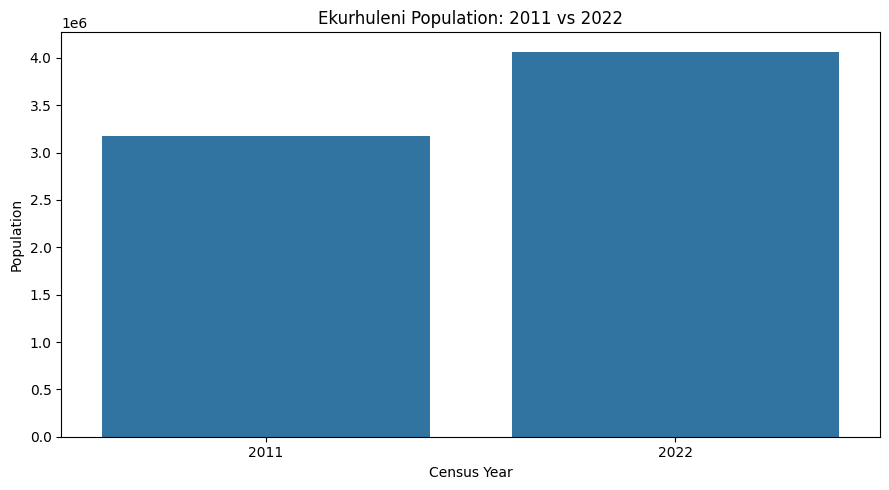

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=census_df,
    x="Year",
    y="Population"
)

plt.title("Ekurhuleni Population: 2011 vs 2022")
plt.xlabel("Census Year")
plt.ylabel("Population")

plt.tight_layout()
plt.show()


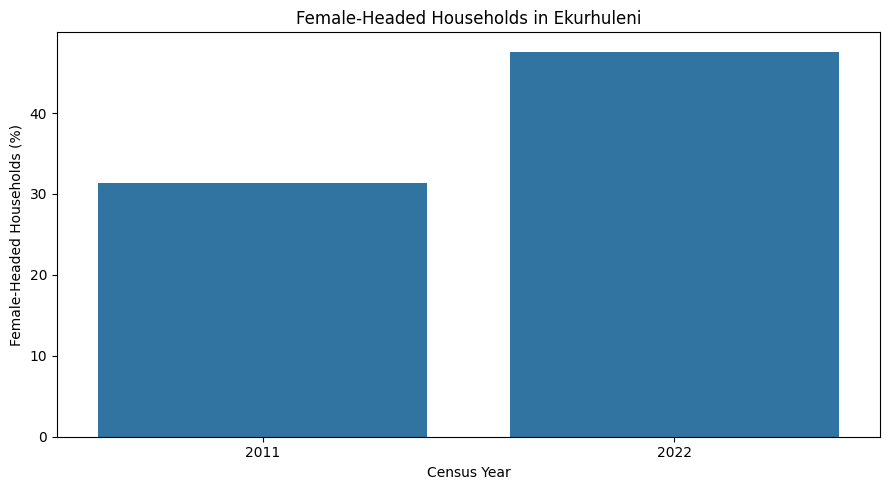

In [ ]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=census_df,
    x="Year",
    y="Female_Headed_Households_Percent"
)

plt.title("Female-Headed Households in Ekurhuleni")
plt.xlabel("Census Year")
plt.ylabel("Female-Headed Households (%)")

plt.tight_layout()
plt.show()



## Integration of SAPS and Stats SA Data

Two credible South African data sources
were used in this project.

### Dataset 1: SAPS Crime Statistics

The SAPS dataset provides historical
recorded crime counts at police-station
level across financial years.

It is used for:

- Hotspot classification
- Temporal crime analysis
- Spatial visualisation
- Machine Learning prediction
- Pattern discovery

### Dataset 2: Stats SA Census 2022

The Census dataset provides population
and household indicators for Ekurhuleni.

It is used for:

- Demographic context
- Historical population comparison
- Household indicator comparison
- Interpretation of crime-count limitations

### Relationship Between Datasets

Ekurhuleni's population increased between
2011 and 2022.

This population change demonstrates why
raw crime counts require careful
interpretation.

The SAPS data and Census data have
different geographic and temporal units.

SAPS observations refer to police stations
and financial years.

The Census observations refer to the
whole municipality and census years.

The Census population cannot be assigned
to individual police stations to calculate
station-specific crime rates.

### Limitations

These datasets do not establish a causal
relationship between demographic change
and recorded crime.

The available police crime records do not
identify female victims for all selected
crime categories.

Therefore, the project investigates
general violent-crime hotspots relevant
to community safety, not directly
measured violence against women.


In [ ]:


path = "dashboard_data/census_ekurhuleni.csv"

if os.path.exists(path):
    check_df = pd.read_csv(path)

    print("Census dataset successfully integrated!")
    print("Shape:", check_df.shape)
    print("Missing values:",
          check_df.isnull().sum().sum())

    display(check_df)
else:
    print("Census dataset file is missing.")


Census dataset successfully integrated!
Shape: (2, 7)
Missing values: 0


,Year,Municipality,Population,Median_Age,Average_Household_Size,Female_Headed_Households_Percent,Formal_Dwellings_Percent
0,2011,Ekurhuleni,3178470,27,3.1,31.3,77.4
1,2022,Ekurhuleni,4066691,30,2.9,47.6,88.2


In [ ]:

import os
import shutil
from google.colab import files

# Confirm Census data is included
assert os.path.exists(
    "dashboard_data/census_ekurhuleni.csv"
)

# Create the updated ZIP files
shutil.make_archive(
    "Ekurhuleni_Dashboard_Data_FINAL",
    "zip",
    root_dir=".",
    base_dir="dashboard_data"
)

shutil.make_archive(
    "Ekurhuleni_Trained_Models_FINAL",
    "zip",
    root_dir=".",
    base_dir="models"
)

print("Dashboard files:",
      len(os.listdir("dashboard_data")))

print("Model files:",
      len(os.listdir("models")))

files.download(
    "Ekurhuleni_Dashboard_Data_FINAL.zip"
)

files.download(
    "Ekurhuleni_Trained_Models_FINAL.zip"
)


Dashboard files: 15
Model files: 8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# STAGE 12: COMPUTATIONAL COMPLEXITY ANALYSIS

## Introduction

Computational complexity examines how much
time and processing power Machine Learning
algorithms require.

This project compares the training and
prediction times of three algorithms:

1. Logistic Regression
2. Decision Tree
3. Random Forest

The purpose is to compare computational
efficiency without changing the previously
trained models or their evaluation results.


In [ ]:

# STAGE 12: COMPUTATIONAL COMPLEXITY ANALYSIS

import time
import pandas as pd
import os
from sklearn.base import clone

# Compare temporary copies of the trained models
runtime_results = []

for name, fitted_model in models.items():

    model_copy = clone(fitted_model)

    start = time.perf_counter()
    model_copy.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    start = time.perf_counter()
    model_copy.predict(X_val)
    prediction_time = time.perf_counter() - start

    runtime_results.append({
        "Model": name,
        "Training_Time_Seconds": training_time,
        "Prediction_Time_Seconds": prediction_time
    })

runtime_df = pd.DataFrame(runtime_results)

display(runtime_df)

os.makedirs("dashboard_data", exist_ok=True)

runtime_df.to_csv(
    "dashboard_data/complexity_results.csv",
    index=False
)

print("Complexity analysis completed!")


,Model,Training_Time_Seconds,Prediction_Time_Seconds
0,Logistic Regression,0.045664,0.005117
1,Decision Tree,0.010337,0.003548
2,Random Forest,0.315514,0.038638


Complexity analysis completed!



## Computational Complexity Results and Interpretation

Three classification algorithms were
compared using measured training and
prediction execution times.

### Logistic Regression

- Training time: 0.045664 seconds
- Prediction time: 0.005117 seconds

### Decision Tree

- Training time: 0.010337 seconds
- Prediction time: 0.003548 seconds

### Random Forest

- Training time: 0.315514 seconds
- Prediction time: 0.038638 seconds

### Interpretation

Decision Tree was the fastest algorithm
in both training and prediction.

Logistic Regression required slightly
more execution time than Decision Tree
but substantially less than Random Forest.

Random Forest was the slowest because
it combines multiple decision trees.

Although Decision Tree was fastest,
Logistic Regression achieved the highest
validation F1-score of 0.9000.

Therefore, Logistic Regression remained
the selected classification model.

### Limitations

The execution times were measured during
one Google Colab run.

Different hardware, dataset sizes and
runtime conditions may produce different
results.

These measurements represent empirical
runtime rather than formal theoretical
time-complexity estimates.

The experiment used temporary model
copies and did not change the original
trained models or test results.



# FINAL PROJECT CONCLUSION

This project developed a Machine Learning
solution for analysing recorded violent-crime
hotspots and historical patterns across
Ekurhuleni police-station areas.

Historical SAPS crime statistics were used
for data preparation, EDA, feature engineering,
hotspot classification and pattern discovery.

Logistic Regression, Decision Tree and
Random Forest models were compared.

Logistic Regression was selected based on
validation F1-score and achieved a final
test accuracy of 94.44%, with an F1-score
of 89.66%.

K-Means clustering and temporal analysis
were used to examine similarities and
changes in recorded crime patterns.

Stats SA Census data provided municipality-
level demographic context.

An interactive Streamlit dashboard was
developed to communicate the findings.

The results identify relative concentrations
of recorded violent-crime counts rather than
female-specific victimisation or individual
safety risk. They support further investigation
and evidence-informed prevention planning.


# AI TOOL USAGE DECLARATION

## Artificial Intelligence Tool Used

**Tool:** ChatGPT  
**Developer:** OpenAI  
**Project:** A Machine Learning Solution for Identifying Women's Safety Hotspots and Crime Patterns in Ekurhuleni

## Purpose of Using Artificial Intelligence

ChatGPT was used as an AI-assisted learning, programming and problem-solving tool during the development of this Machine Learning project.

The tool provided guidance, explanations, code suggestions and debugging assistance throughout different stages of the project.

## Areas Where ChatGPT Was Used

1. **Problem Understanding and Planning**
   - Understanding the project requirements.
   - Planning the Machine Learning workflow.
   - Identifying suitable approaches for crime hotspot classification and pattern discovery.

2. **Data Preparation and Exploratory Data Analysis**
   - Guidance on cleaning and preparing datasets.
   - Suggestions for appropriate data visualisations.
   - Assistance with interpreting histograms, bar graphs, correlation heatmaps and scatter plots.

3. **Machine Learning Development**
   - Explaining Logistic Regression, Decision Tree and Random Forest algorithms.
   - Supporting model training and evaluation.
   - Explaining accuracy, precision, recall, F1-score and confusion matrices.

4. **Hotspot Analysis and Pattern Discovery**
   - Guidance on defining crime hotspots.
   - Explaining K-Means clustering.
   - Assistance with interpreting historical crime patterns and hotspot comparisons.

5. **Programming and Debugging**
   - Suggestions for Python code implementation.
   - Assistance with identifying and resolving programming errors.
   - Guidance on organising notebook sections and interpreting outputs.

6. **Dashboard Development and Deployment**
   - Guidance on developing the Streamlit dashboard.
   - Assistance with GitHub repository setup.
   - Support with deployment and troubleshooting.

7. **Documentation and Reporting**
   - Assistance with writing Markdown explanations.
   - Guidance on computational complexity analysis.
   - Support with documenting model limitations and interpreting results.

## Data Integrity and Responsible AI Use

The project used real historical crime statistics and demographic information from the identified data sources.

ChatGPT was not treated as a source of historical crime observations. The reported analysis and model evaluation results were obtained from the project's datasets and Python computations.

AI-generated suggestions and explanations were reviewed against the project's code, outputs and objectives.

The limitations of the analysis, including the absence of consistently female-specific victim data and the distinction between hotspot classification and numerical forecasting, were documented.

## Acknowledgement

I acknowledge the use of **OpenAI's ChatGPT** as an AI assistance tool during this project.

ChatGPT supported my learning, programming, debugging, analytical interpretation and documentation. The submitted notebook, datasets, model outputs and dashboard provide evidence of the work performed.

**AI Tool Reference:**  
OpenAI. (2026). *ChatGPT* [Large language model]. https://chatgpt.com/